# Projeto 5 — Dois aplicativos de delivery

## Comparação dos tempos de entrega de RapidoJa e ComeBem

Uma rede de restaurantes precisa escolher com qual dos dois aplicativos renovará seu contrato. Ambos anunciam entregas em **35 minutos**. Quando o tempo de uma entrega **ultrapassa 50 minutos**, a rede concede um desconto ao cliente. A análise busca identificar qual serviço apresenta desempenho mais adequado, considerando o tempo típico, a regularidade das entregas e o risco de desconto.

**Pergunta de pesquisa:** qual aplicativo a rede deve manter?

**Unidade de análise:** um pedido.  
**Fonte:** `data/p05_delivery.csv`, com 10.000 pedidos recentes.  
**Variáveis:** `app` (aplicativo), `distancia_km` (distância em quilômetros) e `tempo_min` (tempo entre pedido e entrega, em minutos).

Neste trabalho, os 10.000 pedidos do arquivo formam a **população do exercício**. As amostras usadas nas etapas seguintes serão sorteadas desse banco sem reposição, com tamanhos e sementes registrados. Os testes de hipótese usarão nível de significância de **5%**.

---

## Preparação dos dados

Antes da análise estatística, importamos as bibliotecas, lemos o CSV e verificamos sua estrutura. Essa conferência evita interpretar resultados calculados sobre colunas incorretas, valores ausentes ou um arquivo diferente do previsto.

`pandas` organiza os dados em tabelas; `numpy` ajuda a definir intervalos numéricos; `matplotlib` e `seaborn` produzem os gráficos. `Path` representa o caminho do arquivo, e `display` exibe tabelas no notebook.

In [ ]:
#importando as bibliotecas

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

In [6]:
#mantendo a mesma ordem e a mesma cor em todos gráficos comparativos
ORDEM_APPS = ["RapidoJa", "ComeBem"]
CORES = {"RapidoJa": "#187B91", "ComeBem": "#D57950"}

#definindo um padrão visual
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 180,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "font.family": "DejaVu Sans",
})

### Leitura do arquivo

In [7]:
CAMINHO_DADOS = Path("data") / "p05_delivery.csv"

if not CAMINHO_DADOS.is_file():
    raise FileNotFoundError(
        f"CSV não encontrado em {CAMINHO_DADOS.resolve()}. "
        "Confira se o notebook está na raiz do repositório e se existe a pasta data."
    )

dados = pd.read_csv(CAMINHO_DADOS)

print(f"Arquivo: {CAMINHO_DADOS}")
print(f"Pedidos: {len(dados):,} | Colunas: {dados.shape[1]}")
display(dados.head())

Arquivo: data\p05_delivery.csv
Pedidos: 10,000 | Colunas: 3


,app,distancia_km,tempo_min
0,ComeBem,3.4,31.9
1,RapidoJa,3.7,44.4
2,RapidoJa,2.8,26.5
3,ComeBem,3.3,21.7
4,ComeBem,3.2,38.9


### Conferência da estrutura

Confirmamos nomes das colunas, número de registros, tipos numéricos, categorias esperadas e ausência de valores faltantes. 

In [8]:
COLUNAS_ESPERADAS = ["app", "distancia_km", "tempo_min"]

assert list(dados.columns) == COLUNAS_ESPERADAS
assert len(dados) == 10_000
assert set(dados["app"].unique()) == set(ORDEM_APPS)
assert dados.isna().sum().sum() == 0
assert dados[["distancia_km", "tempo_min"]].gt(0).all().all()

print("Dimensão da base:", dados.shape)

display(pd.DataFrame({
    "Tipo": dados.dtypes.astype(str),
    "Valores ausentes": dados.isna().sum(),
}))

print("Pedidos por aplicativo:")
display(dados["app"].value_counts().rename("Pedidos").to_frame())

Dimensão da base: (10000, 3)


,Tipo,Valores ausentes
app,str,0
distancia_km,float64,0
tempo_min,float64,0


Pedidos por aplicativo:


,Pedidos
app,
RapidoJa,5011
ComeBem,4989


---

## 1. Descrição dos tempos de entrega

Nesta etapa, comparamos os tempos de entrega no banco completo e em cada aplicativo. Queremos saber tanto qual é o tempo típico quanto o quanto os tempos variam.

A **média** considera todos os tempos; a **mediana** é o valor central depois de ordená-los. O **desvio padrão** mede a dispersão em minutos. Os quartis Q1 e Q3 delimitam a metade central dos pedidos, e a amplitude interquartil é a diferença `Q3 − Q1`.

Como estamos descrevendo o banco completo, tratado no exercício como população, calculamos desvio padrão e variância com `ddof=0`.

### 1.1 Medidas descritivas

As tabelas apresentam primeiro as medidas de centro, depois as de dispersão e, por fim, os valores extremos. A linha “Total” reúne os dois aplicativos.

In [9]:
rapidoja = dados[dados["app"] == "RapidoJa"]
comebem = dados[dados["app"] == "ComeBem"]

print("Pedidos RapidoJa:", len(rapidoja))
print("Aplicativo presente em rapidoja:", rapidoja["app"].unique())

print("\nPedidos ComeBem:", len(comebem))
print("Aplicativo presente em comebem:", comebem["app"].unique())

print("\nTotal dos dois grupos:", len(rapidoja) + len(comebem))

display(rapidoja.head(3))
display(comebem.head(3))

Pedidos RapidoJa: 5011
Aplicativo presente em rapidoja: <StringArray>
['RapidoJa']
Length: 1, dtype: str

Pedidos ComeBem: 4989
Aplicativo presente em comebem: <StringArray>
['ComeBem']
Length: 1, dtype: str

Total dos dois grupos: 10000


,app,distancia_km,tempo_min
1,RapidoJa,3.7,44.4
2,RapidoJa,2.8,26.5
6,RapidoJa,4.3,29.1


,app,distancia_km,tempo_min
0,ComeBem,3.4,31.9
3,ComeBem,3.3,21.7
4,ComeBem,3.2,38.9


#### Medidas de centro

Calculamos média, mediana e moda do tempo de entrega no banco completo e em cada aplicativo. A média usa todos os tempos; a mediana é o valor central dos tempos ordenados; a moda é o tempo registrado com maior frequência.

In [10]:
media_total = dados["tempo_min"].mean()
media_rapidoja = rapidoja["tempo_min"].mean()
media_comebem = comebem["tempo_min"].mean()

mediana_total = dados["tempo_min"].median()
mediana_rapidoja = rapidoja["tempo_min"].median()
mediana_comebem = comebem["tempo_min"].median()

moda_total = dados["tempo_min"].mode().tolist()
moda_rapidoja = rapidoja["tempo_min"].mode().tolist()
moda_comebem = comebem["tempo_min"].mode().tolist()

print("BANCO COMPLETO")
print(f"Média: {media_total:.2f} min")
print(f"Mediana: {mediana_total:.2f} min")
print("Moda(s):", moda_total)

print("\nRAPIDOJA")
print(f"Média: {media_rapidoja:.2f} min")
print(f"Mediana: {mediana_rapidoja:.2f} min")
print("Moda(s):", moda_rapidoja)

print("\nCOMEBEM")
print(f"Média: {media_comebem:.2f} min")
print(f"Mediana: {mediana_comebem:.2f} min")
print("Moda(s):", moda_comebem)

BANCO COMPLETO
Média: 34.97 min
Mediana: 35.00 min
Moda(s): [34.8, 37.0]

RAPIDOJA
Média: 34.91 min
Mediana: 35.00 min
Moda(s): [33.1]

COMEBEM
Média: 35.02 min
Mediana: 34.90 min
Moda(s): [37.0]


#### Medidas de dispersão

A média indica o centro, mas não mostra o quanto os tempos variam. Por isso, comparamos o desvio padrão e a variância. Como estamos descrevendo o banco completo, tratado como população neste exercício, usamos `ddof=0`.

In [11]:
desvio_total = dados["tempo_min"].std(ddof=0)
desvio_rapidoja = rapidoja["tempo_min"].std(ddof=0)
desvio_comebem = comebem["tempo_min"].std(ddof=0)

variancia_total = dados["tempo_min"].var(ddof=0)
variancia_rapidoja = rapidoja["tempo_min"].var(ddof=0)
variancia_comebem = comebem["tempo_min"].var(ddof=0)

print("BANCO COMPLETO")
print(f"Desvio padrão: {desvio_total:.2f} min")
print(f"Variância: {variancia_total:.2f} min²")

print("\nRAPIDOJA")
print(f"Desvio padrão: {desvio_rapidoja:.2f} min")
print(f"Variância: {variancia_rapidoja:.2f} min²")

print("\nCOMEBEM")
print(f"Desvio padrão: {desvio_comebem:.2f} min")
print(f"Variância: {variancia_comebem:.2f} min²")

BANCO COMPLETO
Desvio padrão: 9.12 min
Variância: 83.20 min²

RAPIDOJA
Desvio padrão: 5.06 min
Variância: 25.61 min²

COMEBEM
Desvio padrão: 11.88 min
Variância: 141.05 min²


#### Quartis e valores extremos

Q1 é o tempo abaixo do qual estão 25% dos pedidos; Q3 é o tempo abaixo do qual estão 75%. A diferença entre eles, chamada amplitude interquartil (AIQ), mostra a largura da metade central dos tempos. Também verificamos o menor e o maior tempo observado.

In [12]:
q1_rapidoja = rapidoja["tempo_min"].quantile(0.25)
q3_rapidoja = rapidoja["tempo_min"].quantile(0.75)

q1_comebem = comebem["tempo_min"].quantile(0.25)
q3_comebem = comebem["tempo_min"].quantile(0.75)

print("RAPIDOJA")
print(f"Q1: {q1_rapidoja:.2f} min")
print(f"Q3: {q3_rapidoja:.2f} min")
print(f"AIQ: {q3_rapidoja - q1_rapidoja:.2f} min")
print(f"Mínimo: {rapidoja['tempo_min'].min():.2f} min")
print(f"Máximo: {rapidoja['tempo_min'].max():.2f} min")

print("\nCOMEBEM")
print(f"Q1: {q1_comebem:.2f} min")
print(f"Q3: {q3_comebem:.2f} min")
print(f"AIQ: {q3_comebem - q1_comebem:.2f} min")
print(f"Mínimo: {comebem['tempo_min'].min():.2f} min")
print(f"Máximo: {comebem['tempo_min'].max():.2f} min")

RAPIDOJA
Q1: 31.60 min
Q3: 38.40 min
AIQ: 6.80 min
Mínimo: 18.10 min
Máximo: 52.00 min

COMEBEM
Q1: 27.00 min
Q3: 43.00 min
AIQ: 16.00 min
Mínimo: 3.00 min
Máximo: 73.80 min


### 1.2 Histogramas sobrepostos

Os histogramas permitem comparar a distribuição completa dos tempos. Ambos usam as mesmas faixas de 2 minutos. A linha em 35 minutos marca o tempo anunciado pelos aplicativos, e a linha em 50 minutos marca o limite da política de desconto.

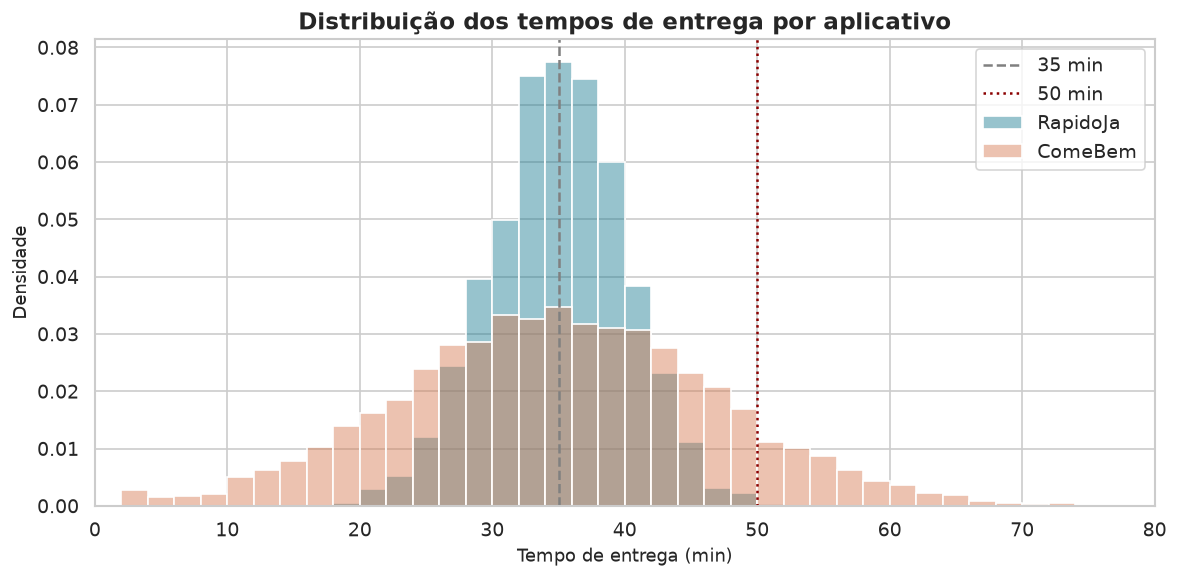

In [13]:
faixas = np.arange(0, 82, 2)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=rapidoja, x="tempo_min", bins=faixas,
    stat="density", color=CORES["RapidoJa"], alpha=0.45,
    label="RapidoJa"
)

sns.histplot(
    data=comebem, x="tempo_min", bins=faixas,
    stat="density", color=CORES["ComeBem"], alpha=0.45,
    label="ComeBem"
)

plt.axvline(35, color="gray", linestyle="--", label="35 min")
plt.axvline(50, color="darkred", linestyle=":", label="50 min")

plt.title("Distribuição dos tempos de entrega por aplicativo")
plt.xlabel("Tempo de entrega (min)")
plt.ylabel("Densidade")
plt.xlim(0, 80)
plt.legend()
plt.tight_layout()
plt.show()

### 1.3 Boxplot

O boxplot mostra a mediana, os quartis e a dispersão dos tempos em cada aplicativo. A altura da caixa corresponde à metade central das entregas, entre Q1 e Q3.

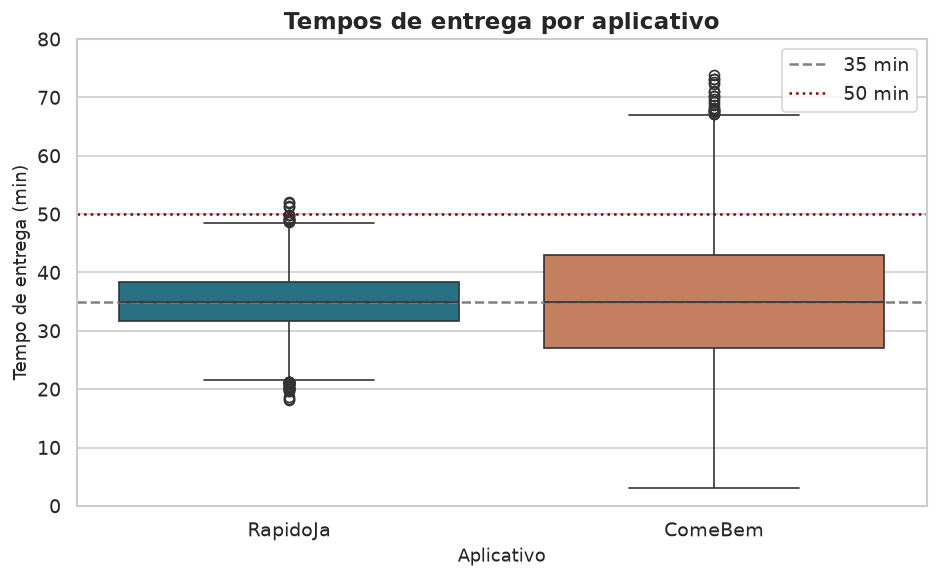

In [14]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=dados,
    x="app",
    y="tempo_min",
    hue="app",
    order=ORDEM_APPS,
    palette=CORES,
    legend=False
)

plt.axhline(35, color="gray", linestyle="--", label="35 min")
plt.axhline(50, color="darkred", linestyle=":", label="50 min")

plt.title("Tempos de entrega por aplicativo")
plt.xlabel("Aplicativo")
plt.ylabel("Tempo de entrega (min)")
plt.ylim(0, 80)
plt.legend()
plt.tight_layout()
plt.show()

#### 1.3.1 Violin plot

O violin plot mostra a distribuição dos tempos de cada aplicativo. As partes mais largas indicam tempos mais frequentes. As linhas internas marcam os quartis e a mediana.

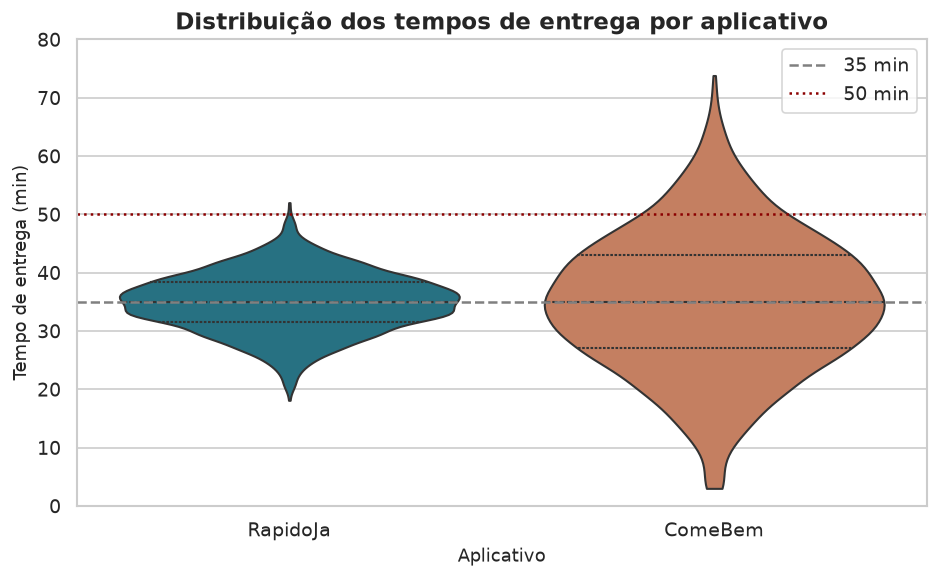

In [15]:
plt.figure(figsize=(8, 5))

sns.violinplot(
    data=dados,
    x="app",
    y="tempo_min",
    hue="app",
    order=ORDEM_APPS,
    palette=CORES,
    inner="quart",
    cut=0,
    legend=False
)

plt.axhline(35, color="gray", linestyle="--", label="35 min")
plt.axhline(50, color="darkred", linestyle=":", label="50 min")

plt.title("Distribuição dos tempos de entrega por aplicativo")
plt.xlabel("Aplicativo")
plt.ylabel("Tempo de entrega (min)")
plt.ylim(0, 80)
plt.legend()
plt.tight_layout()
plt.show()

### 1.4 Interpretação

Os tempos médios dos aplicativos são próximos: cerca de **34,91 minutos no RapidoJa** e **35,02 minutos no ComeBem**. As medianas também ficam perto de 35 minutos. Portanto, os aplicativos se parecem quanto ao tempo típico.

A diferença mais clara está na dispersão. O desvio padrão é de aproximadamente **5,06 minutos no RapidoJa** e **11,88 minutos no ComeBem**. A metade central dos tempos vai de **31,6 a 38,4 minutos** no RapidoJa, contra **27,0 a 43,0 minutos** no ComeBem. Os histogramas e o boxplot mostram essa diferença: os tempos do RapidoJa ficam mais concentrados, enquanto os do ComeBem variam mais.

Nesta etapa descrevemos os pedidos observados. A relação dessa variação com os descontos será analisada nas próximas questões.

## 2. Comparação entre amostras e banco completo

Sorteamos, do banco de 10.000 pedidos, amostras de 10, 30, 100 e 1.000 pedidos. Para cada tamanho, comparamos o histograma, a média e o desvio padrão com os valores do banco completo.

Os sorteios são feitos sem reposição: um mesmo pedido não aparece duas vezes dentro da mesma amostra. Usamos uma semente fixa para conseguir repetir os resultados.

In [17]:
semente = 67

amostra_10 = dados.sample(n=10, replace=False, random_state=semente)
amostra_30 = dados.sample(n=30, replace=False, random_state=semente)
amostra_100 = dados.sample(n=100, replace=False, random_state=semente)
amostra_1000 = dados.sample(n=1000, replace=False, random_state=semente)

In [18]:
print("Amostra de 10:", len(amostra_10), "pedidos")
print("Aplicativos:", amostra_10["app"].value_counts().to_dict())

print("\nAmostra de 30:", len(amostra_30), "pedidos")
print("Aplicativos:", amostra_30["app"].value_counts().to_dict())

print("\nAmostra de 100:", len(amostra_100), "pedidos")
print("Aplicativos:", amostra_100["app"].value_counts().to_dict())

print("\nAmostra de 1000:", len(amostra_1000), "pedidos")
print("Aplicativos:", amostra_1000["app"].value_counts().to_dict())

print("\nPrimeiras linhas da amostra de 10:")
display(amostra_10.head())

Amostra de 10: 10 pedidos
Aplicativos: {'ComeBem': 6, 'RapidoJa': 4}

Amostra de 30: 30 pedidos
Aplicativos: {'ComeBem': 16, 'RapidoJa': 14}

Amostra de 100: 100 pedidos
Aplicativos: {'ComeBem': 53, 'RapidoJa': 47}

Amostra de 1000: 1000 pedidos
Aplicativos: {'RapidoJa': 536, 'ComeBem': 464}

Primeiras linhas da amostra de 10:


,app,distancia_km,tempo_min
1348,ComeBem,3.6,21.3
4774,ComeBem,4.8,37.0
5562,ComeBem,3.0,45.0
1380,RapidoJa,5.0,45.7
1361,RapidoJa,4.0,26.7


### Médias e desvios padrão

A média mostra o tempo central de cada conjunto. O desvio padrão mostra quanto os tempos variam em torno da média. Para o banco completo, tratado como população do exercício, usamos `ddof=0`. Para cada amostra, usamos `ddof=1`.

In [19]:
comparacao = pd.DataFrame({
    "Conjunto": ["Banco completo", "Amostra 10", "Amostra 30",
                 "Amostra 100", "Amostra 1000"],
    "Pedidos": [len(dados), len(amostra_10), len(amostra_30),
                len(amostra_100), len(amostra_1000)],
    "Média (min)": [
        dados["tempo_min"].mean(),
        amostra_10["tempo_min"].mean(),
        amostra_30["tempo_min"].mean(),
        amostra_100["tempo_min"].mean(),
        amostra_1000["tempo_min"].mean(),
    ],
    "Desvio padrão (min)": [
        dados["tempo_min"].std(ddof=0),
        amostra_10["tempo_min"].std(ddof=1),
        amostra_30["tempo_min"].std(ddof=1),
        amostra_100["tempo_min"].std(ddof=1),
        amostra_1000["tempo_min"].std(ddof=1),
    ],
})

display(comparacao.round(2))

,Conjunto,Pedidos,Média (min),Desvio padrão (min)
0,Banco completo,10000,34.97,9.12
1,Amostra 10,10,35.91,10.09
2,Amostra 30,30,35.02,9.54
3,Amostra 100,100,34.58,8.72
4,Amostra 1000,1000,34.77,8.68


### Histogramas das amostras

Em cada gráfico, o contorno cinza representa o banco completo e as barras azuis representam uma amostra. Todos usam as mesmas faixas de 5 minutos e os mesmos limites dos eixos, para que as diferenças visuais não sejam causadas por escalas diferentes.

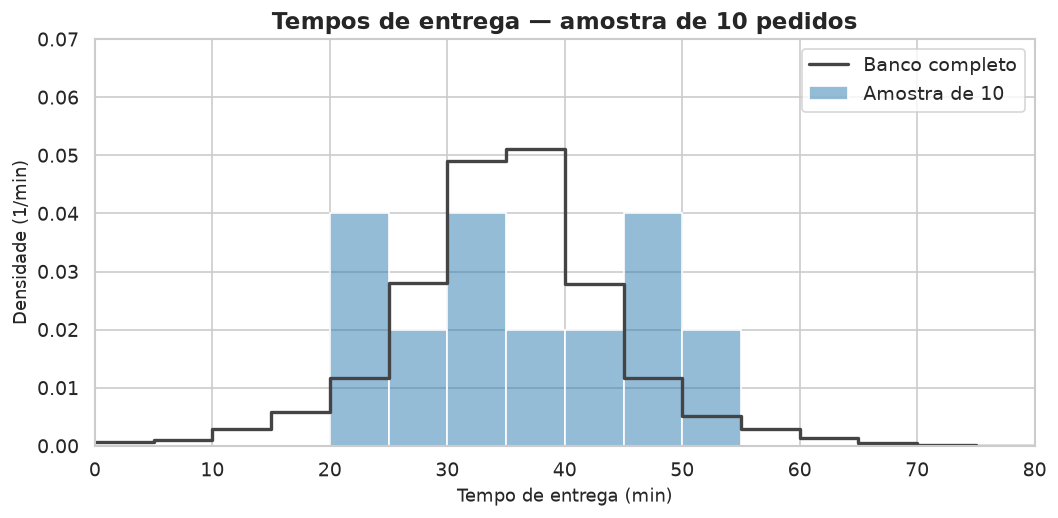

In [20]:
faixas = np.arange(0, 85, 5)

plt.figure(figsize=(9, 4.5))

sns.histplot(data=dados, x="tempo_min", bins=faixas, stat="density",
             element="step", fill=False, color="#444444",
             linewidth=2, label="Banco completo")

sns.histplot(data=amostra_10, x="tempo_min", bins=faixas, stat="density",
             color="#2A7AB0", alpha=0.5, label="Amostra de 10")

plt.title("Tempos de entrega — amostra de 10 pedidos")
plt.xlabel("Tempo de entrega (min)")
plt.ylabel("Densidade (1/min)")
plt.xlim(0, 80)
plt.ylim(0, 0.07)
plt.legend()
plt.tight_layout()
plt.show()

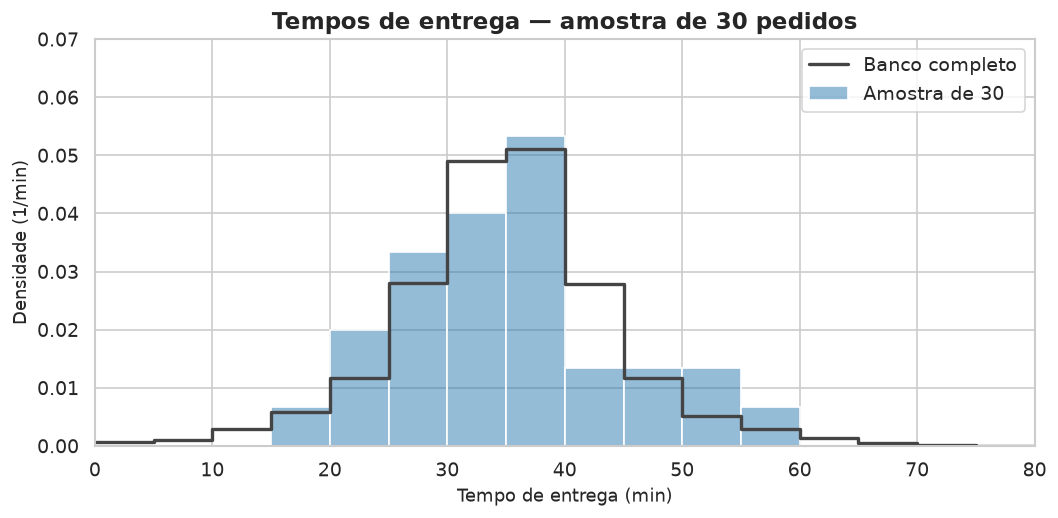

In [21]:
plt.figure(figsize=(9, 4.5))

sns.histplot(data=dados, x="tempo_min", bins=faixas, stat="density",
             element="step", fill=False, color="#444444",
             linewidth=2, label="Banco completo")

sns.histplot(data=amostra_30, x="tempo_min", bins=faixas, stat="density",
             color="#2A7AB0", alpha=0.5, label="Amostra de 30")

plt.title("Tempos de entrega — amostra de 30 pedidos")
plt.xlabel("Tempo de entrega (min)")
plt.ylabel("Densidade (1/min)")
plt.xlim(0, 80)
plt.ylim(0, 0.07)
plt.legend()
plt.tight_layout()
plt.show()

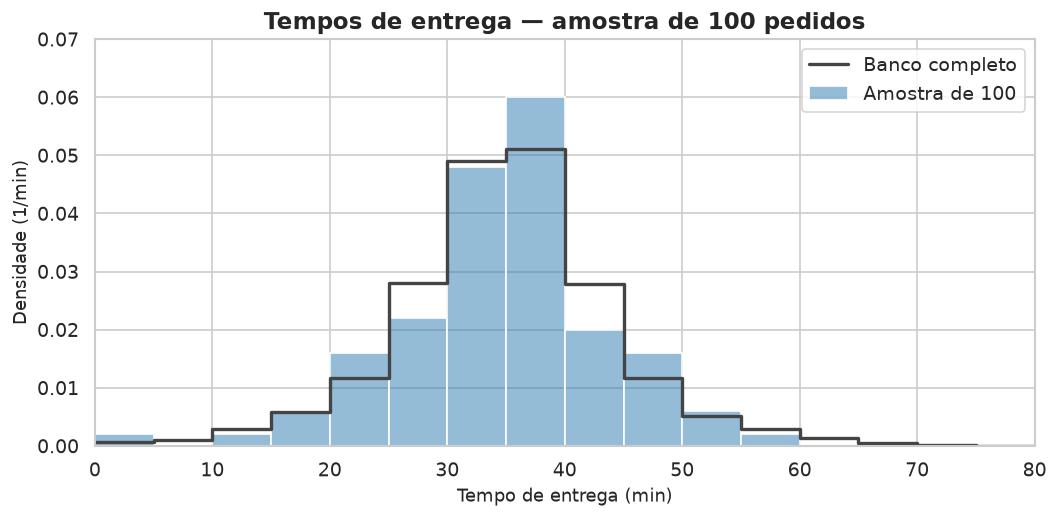

In [22]:
plt.figure(figsize=(9, 4.5))

sns.histplot(data=dados, x="tempo_min", bins=faixas, stat="density",
             element="step", fill=False, color="#444444",
             linewidth=2, label="Banco completo")

sns.histplot(data=amostra_100, x="tempo_min", bins=faixas, stat="density",
             color="#2A7AB0", alpha=0.5, label="Amostra de 100")

plt.title("Tempos de entrega — amostra de 100 pedidos")
plt.xlabel("Tempo de entrega (min)")
plt.ylabel("Densidade (1/min)")
plt.xlim(0, 80)
plt.ylim(0, 0.07)
plt.legend()
plt.tight_layout()
plt.show()

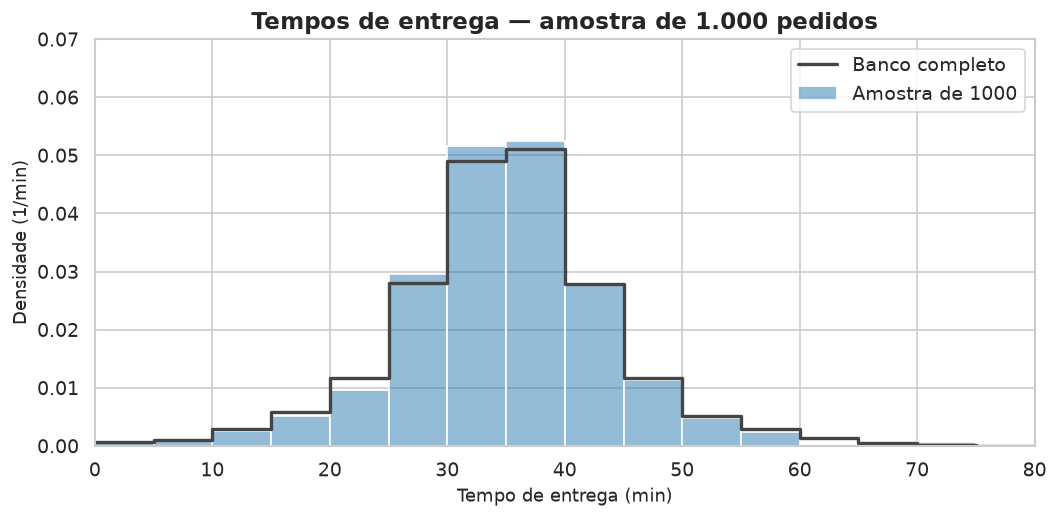

In [23]:
plt.figure(figsize=(9, 4.5))

sns.histplot(data=dados, x="tempo_min", bins=faixas, stat="density",
             element="step", fill=False, color="#444444",
             linewidth=2, label="Banco completo")

sns.histplot(data=amostra_1000, x="tempo_min", bins=faixas, stat="density",
             color="#2A7AB0", alpha=0.5, label="Amostra de 1000")

plt.title("Tempos de entrega — amostra de 1.000 pedidos")
plt.xlabel("Tempo de entrega (min)")
plt.ylabel("Densidade (1/min)")
plt.xlim(0, 80)
plt.ylim(0, 0.07)
plt.legend()
plt.tight_layout()
plt.show()

### Interpretação

O banco completo tem média de **34,97 minutos** e desvio padrão de **9,12 minutos**. Nas amostras, as médias ficaram entre **33,49** e **35,18 minutos**, e os desvios padrão entre **7,67** e **9,43 minutos**.

O histograma da amostra de 10 pedidos é irregular, pois poucos pedidos representam cada faixa de tempo. Conforme o tamanho cresce, o formato observado passa a mostrar mais detalhes da distribuição do banco completo. A amostra de 1.000 pedidos apresenta uma forma bem mais próxima da população.

A proximidade numérica não melhora obrigatoriamente a cada tamanho em um único sorteio. Neste caso, por acaso, a média da amostra de 10 ficou mais perto da média populacional que a da amostra de 1.000. Amostras maiores reduzem a variação esperada **entre muitos sorteios**, mas não garantem que cada amostra individual seja a mais próxima possível da população.

## 3. Normalidade dos tempos de entrega

Verificamos se a distribuição de `tempo_min` se aproxima de uma distribuição normal no banco completo e em cada aplicativo separadamente.

No teste de Shapiro–Wilk, **H₀** afirma que os dados seguem uma distribuição normal; **H₁** afirma que não seguem. Usamos α = 0,05. Também examinamos gráficos Q–Q: se os pontos acompanharem aproximadamente a reta, a distribuição se aproxima da normal.

O Shapiro–Wilk é um teste de forma da distribuição, não um teste uni ou bicaudal de médias. A rejeição ocorre para valores suficientemente baixos da estatística W.

In [24]:
from scipy import stats

semente_normalidade = 67

tempos_total_shapiro = dados["tempo_min"].sample(
    n=5000, replace=False, random_state=semente_normalidade
)

tempos_rapidoja_shapiro = rapidoja["tempo_min"].sample(
    n=5000, replace=False, random_state=semente_normalidade
)

tempos_comebem_shapiro = comebem["tempo_min"]

print("Total — pedidos usados no Shapiro:", len(tempos_total_shapiro))
print("RapidoJa — pedidos usados no Shapiro:", len(tempos_rapidoja_shapiro))
print("ComeBem — pedidos usados no Shapiro:", len(tempos_comebem_shapiro))

Total — pedidos usados no Shapiro: 5000
RapidoJa — pedidos usados no Shapiro: 5000
ComeBem — pedidos usados no Shapiro: 4989


In [25]:
teste_total = stats.shapiro(tempos_total_shapiro)
teste_rapidoja = stats.shapiro(tempos_rapidoja_shapiro)
teste_comebem = stats.shapiro(tempos_comebem_shapiro)

print("TODOS OS PEDIDOS")
print(f"W = {teste_total.statistic:.4f}")
print(f"p = {teste_total.pvalue:.3e}")

print("\nRAPIDOJA")
print(f"W = {teste_rapidoja.statistic:.4f}")
print(f"p = {teste_rapidoja.pvalue:.3e}")

print("\nCOMEBEM")
print(f"W = {teste_comebem.statistic:.4f}")
print(f"p = {teste_comebem.pvalue:.3e}")

TODOS OS PEDIDOS
W = 0.9814
p = 3.884e-25

RAPIDOJA
W = 0.9990
p = 5.658e-03

COMEBEM
W = 0.9991
p = 1.019e-02


### Gráficos Q–Q

Cada gráfico compara os quantis observados dos tempos com os quantis esperados de uma distribuição normal. Pontos próximos da reta sugerem aproximação à normalidade; curvas e afastamentos nas pontas indicam diferenças, especialmente nas caudas. Usamos os dados completos nos três gráficos para enxergar sua forma.

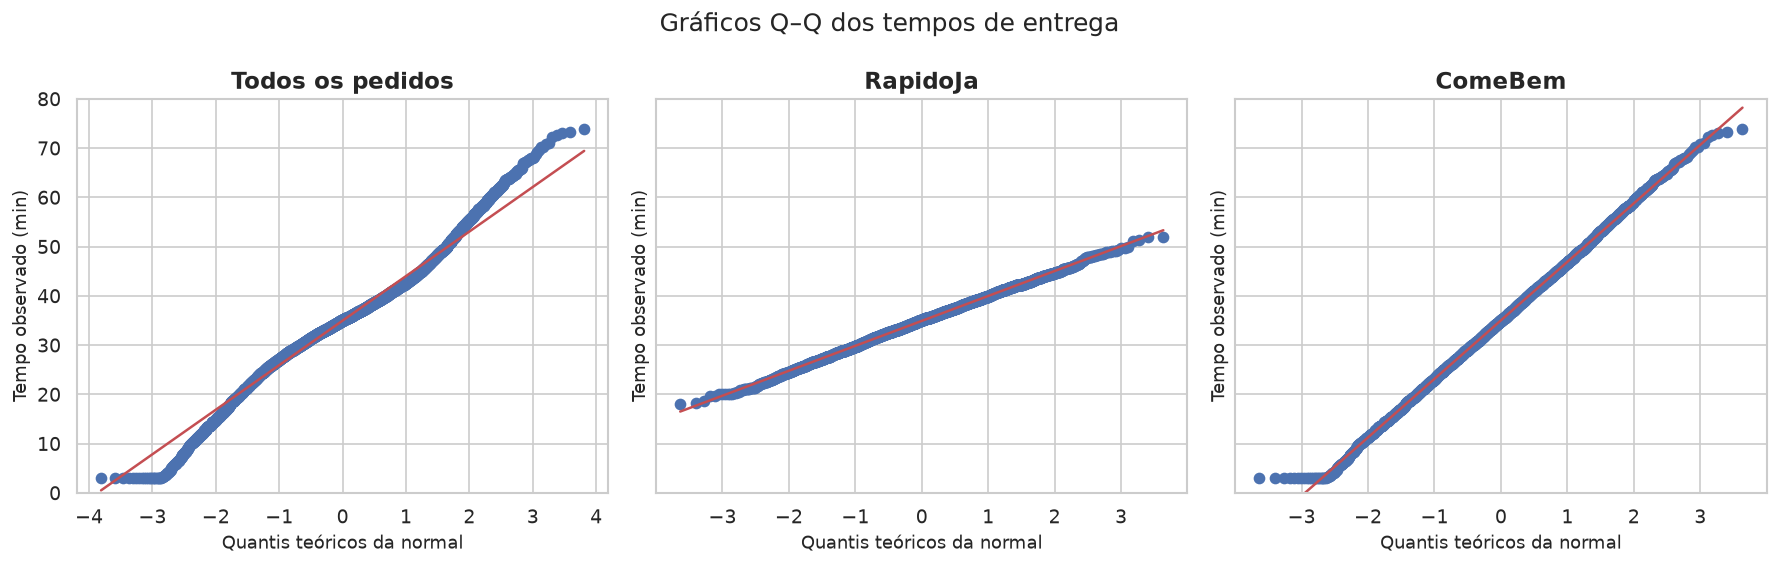

In [26]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)

stats.probplot(dados["tempo_min"], dist="norm", plot=eixos[0])
eixos[0].set_title("Todos os pedidos")
eixos[0].set_xlabel("Quantis teóricos da normal")
eixos[0].set_ylabel("Tempo observado (min)")
eixos[0].set_ylim(0, 80)

stats.probplot(rapidoja["tempo_min"], dist="norm", plot=eixos[1])
eixos[1].set_title("RapidoJa")
eixos[1].set_xlabel("Quantis teóricos da normal")
eixos[1].set_ylabel("Tempo observado (min)")
eixos[1].set_ylim(0, 80)

stats.probplot(comebem["tempo_min"], dist="norm", plot=eixos[2])
eixos[2].set_title("ComeBem")
eixos[2].set_xlabel("Quantis teóricos da normal")
eixos[2].set_ylabel("Tempo observado (min)")
eixos[2].set_ylim(0, 80)

fig.suptitle("Gráficos Q–Q dos tempos de entrega")
fig.tight_layout()
plt.show()

### Interpretação

Com α = 0,05, o teste de Shapiro–Wilk rejeitou a hipótese de normalidade nos três conjuntos: banco completo, RapidoJa e ComeBem. O resultado foi mais distante da normalidade no banco completo, com W próximo de **0,981**. Nos aplicativos separados, W ficou próximo de **0,999**, e os pontos dos gráficos Q–Q acompanharam melhor a reta, embora apresentem pequenos desvios nas extremidades.

A diferença entre o conjunto completo e os grupos separados faz sentido: os aplicativos têm médias parecidas, mas dispersões bastante diferentes. Ao juntar pedidos de distribuições com larguras diferentes, a forma resultante pode se afastar mais de uma normal única. Além disso, com quase 5.000 observações em cada teste, mesmo desvios visuais pequenos podem gerar valores de p abaixo de 0,05.

O Shapiro–Wilk não fornece graus de liberdade nem um tamanho de efeito padronizado como os usados em testes de diferença de médias. Por isso relatamos W, p, o tamanho do conjunto testado e a avaliação visual dos gráficos Q–Q.

## 4. Escore z e probabilidade de atraso

Para cada aplicativo, calculamos o escore z de uma entrega de 50 minutos:

**z = (50 − média) / desvio padrão**

O escore z indica quantos desvios padrão o tempo de 50 minutos está acima da média do aplicativo. Usamos a média e o desvio padrão de todos os pedidos de cada aplicativo (`ddof=0`). Depois estimamos a probabilidade de ultrapassar 50 minutos pela distribuição normal e comparamos com a proporção observada no banco.

In [27]:
media_rapidoja = rapidoja["tempo_min"].mean()
desvio_rapidoja = rapidoja["tempo_min"].std(ddof=0)

media_comebem = comebem["tempo_min"].mean()
desvio_comebem = comebem["tempo_min"].std(ddof=0)

z_50_rapidoja = (50 - media_rapidoja) / desvio_rapidoja
z_50_comebem = (50 - media_comebem) / desvio_comebem

print("RAPIDOJA")
print(f"Média: {media_rapidoja:.2f} min")
print(f"Desvio padrão: {desvio_rapidoja:.2f} min")
print(f"z de 50 min: {z_50_rapidoja:.3f}")

print("\nCOMEBEM")
print(f"Média: {media_comebem:.2f} min")
print(f"Desvio padrão: {desvio_comebem:.2f} min")
print(f"z de 50 min: {z_50_comebem:.3f}")

RAPIDOJA
Média: 34.91 min
Desvio padrão: 5.06 min
z de 50 min: 2.981

COMEBEM
Média: 35.02 min
Desvio padrão: 11.88 min
z de 50 min: 1.261


### Atrasos acima de 50 minutos

Pela normal, a probabilidade procurada é a área à direita do escore z: `P(T > 50)`. No banco, contamos diretamente os pedidos com `tempo_min > 50` e dividimos pelo número de pedidos do aplicativo. Uma entrega de exatamente 50 minutos não entra na contagem de descontos.

In [28]:
prob_normal_rapidoja = stats.norm.sf(z_50_rapidoja)
prob_normal_comebem = stats.norm.sf(z_50_comebem)

atrasos_rapidoja = (rapidoja["tempo_min"] > 50).sum()
atrasos_comebem = (comebem["tempo_min"] > 50).sum()

prop_observada_rapidoja = atrasos_rapidoja / len(rapidoja)
prop_observada_comebem = atrasos_comebem / len(comebem)

print("RAPIDOJA")
print(f"Probabilidade pela normal: {prob_normal_rapidoja:.2%}")
print(f"Pedidos acima de 50 min: {atrasos_rapidoja} de {len(rapidoja)}")
print(f"Proporção observada: {prop_observada_rapidoja:.2%}")

print("\nCOMEBEM")
print(f"Probabilidade pela normal: {prob_normal_comebem:.2%}")
print(f"Pedidos acima de 50 min: {atrasos_comebem} de {len(comebem)}")
print(f"Proporção observada: {prop_observada_comebem:.2%}")

RAPIDOJA
Probabilidade pela normal: 0.14%
Pedidos acima de 50 min: 4 de 5011
Proporção observada: 0.08%

COMEBEM
Probabilidade pela normal: 10.36%
Pedidos acima de 50 min: 498 de 4989
Proporção observada: 9.98%


,Aplicativo,Pela normal (%),Observada (%)
0,RapidoJa,0.14,0.08
1,ComeBem,10.36,9.98


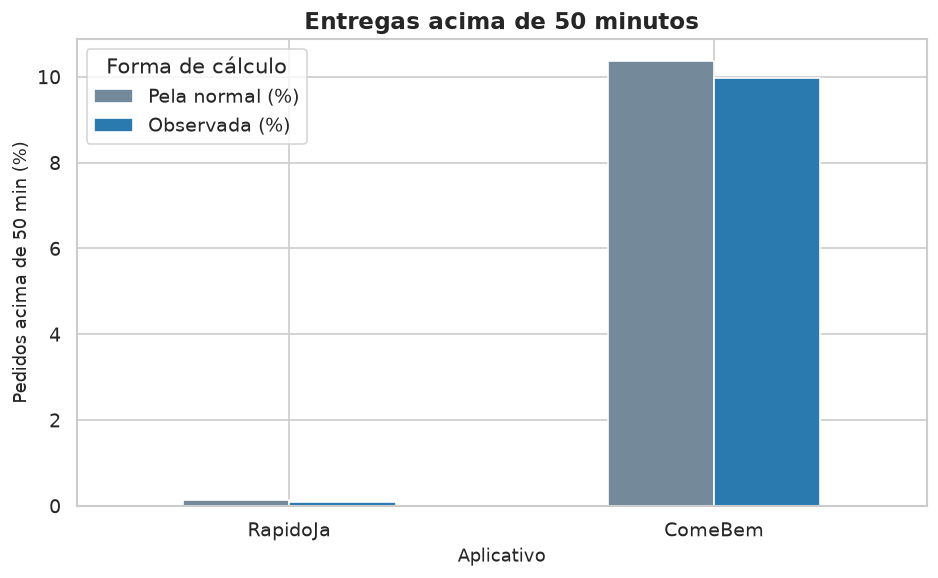

In [29]:
comparacao_50 = pd.DataFrame({
    "Aplicativo": ["RapidoJa", "ComeBem"],
    "Pela normal (%)": [
        prob_normal_rapidoja * 100,
        prob_normal_comebem * 100,
    ],
    "Observada (%)": [
        prop_observada_rapidoja * 100,
        prop_observada_comebem * 100,
    ],
})

display(comparacao_50.round(2))

ax = comparacao_50.set_index("Aplicativo").plot(
    kind="bar",
    figsize=(8, 5),
    color=["#748A9B", "#2A7AB0"],
    rot=0,
)

ax.set_title("Entregas acima de 50 minutos")
ax.set_xlabel("Aplicativo")
ax.set_ylabel("Pedidos acima de 50 min (%)")
ax.legend(title="Forma de cálculo")
plt.tight_layout()
plt.show()

### Uma entrega de 45 minutos é mais incomum em qual aplicativo?

Calculamos a distância de 45 minutos à média de cada aplicativo em unidades de desvio padrão. Como 45 minutos está acima das duas médias, também comparamos a probabilidade normal e a proporção observada de entregas de 45 minutos ou mais.

In [30]:
z_45_rapidoja = (45 - media_rapidoja) / desvio_rapidoja
z_45_comebem = (45 - media_comebem) / desvio_comebem

prob_45_rapidoja = stats.norm.sf(z_45_rapidoja)
prob_45_comebem = stats.norm.sf(z_45_comebem)

prop_45_rapidoja = (rapidoja["tempo_min"] >= 45).mean()
prop_45_comebem = (comebem["tempo_min"] >= 45).mean()

print("RAPIDOJA")
print(f"z de 45 min: {z_45_rapidoja:.3f}")
print(f"Probabilidade normal de 45 min ou mais: {prob_45_rapidoja:.2%}")
print(f"Proporção observada de 45 min ou mais: {prop_45_rapidoja:.2%}")

print("\nCOMEBEM")
print(f"z de 45 min: {z_45_comebem:.3f}")
print(f"Probabilidade normal de 45 min ou mais: {prob_45_comebem:.2%}")
print(f"Proporção observada de 45 min ou mais: {prop_45_comebem:.2%}")

RAPIDOJA
z de 45 min: 1.993
Probabilidade normal de 45 min ou mais: 2.31%
Proporção observada de 45 min ou mais: 1.88%

COMEBEM
z de 45 min: 0.840
Probabilidade normal de 45 min ou mais: 20.04%
Proporção observada de 45 min ou mais: 19.90%


### Comparação visual para 45 minutos

A tabela reúne o escore z e as proporções de entregas de 45 minutos ou mais. O gráfico compara a aproximação normal com a frequência observada em cada aplicativo.

,Aplicativo,z de 45 min,Pedidos com 45 min ou mais,Pela normal (%),Observada (%)
0,RapidoJa,1.99,94,2.31,1.88
1,ComeBem,0.84,993,20.04,19.90


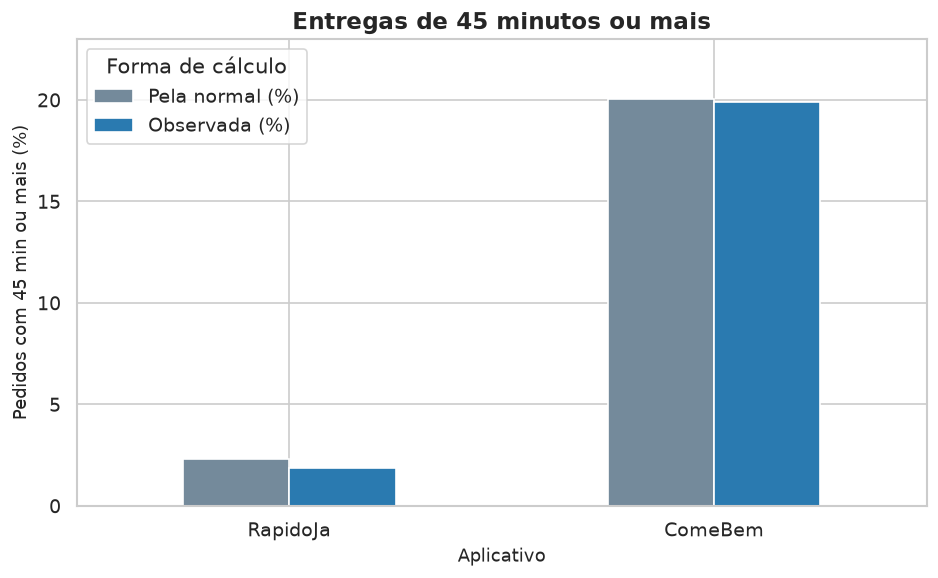

In [31]:
comparacao_45 = pd.DataFrame({
    "Aplicativo": ["RapidoJa", "ComeBem"],
    "z de 45 min": [z_45_rapidoja, z_45_comebem],
    "Pedidos com 45 min ou mais": [
        (rapidoja["tempo_min"] >= 45).sum(),
        (comebem["tempo_min"] >= 45).sum(),
    ],
    "Pela normal (%)": [prob_45_rapidoja * 100, prob_45_comebem * 100],
    "Observada (%)": [prop_45_rapidoja * 100, prop_45_comebem * 100],
})

display(comparacao_45.round(2))

ax = comparacao_45.set_index("Aplicativo")[
    ["Pela normal (%)", "Observada (%)"]
].plot(kind="bar", figsize=(8, 5), color=["#748A9B", "#2A7AB0"], rot=0)

ax.set_title("Entregas de 45 minutos ou mais")
ax.set_xlabel("Aplicativo")
ax.set_ylabel("Pedidos com 45 min ou mais (%)")
ax.set_ylim(0, 23)
ax.legend(title="Forma de cálculo")
plt.tight_layout()
plt.show()

### Interpretação

Uma entrega de 50 minutos está a **2,981 desvios padrão acima da média do RapidoJa** e a **1,261 desvio padrão acima da média do ComeBem**. Pela aproximação normal, a probabilidade de **ultrapassar** 50 minutos é de **0,14%** no RapidoJa e **10,36%** no ComeBem.

Nos pedidos observados, **4 de 5.011 entregas do RapidoJa (0,08%)** e **498 de 4.989 entregas do ComeBem (9,98%)** ultrapassaram 50 minutos. A tabela e o gráfico da seção 4.4 mostram que a aproximação normal e os dados observados apontam na mesma direção: o ComeBem teve uma frequência muito maior de entregas que geram desconto. Os percentuais não são idênticos porque a normal é um modelo aproximado para esses tempos; a etapa 3 já mostrou desvios de normalidade. Isso não permite atribuir a diferença entre os percentuais a uma causa específica.

Uma entrega de **45 minutos é mais incomum no RapidoJa**. Nesse aplicativo, o tempo corresponde a **z = 1,993**, contra **z = 0,840** no ComeBem. Pela aproximação normal, a probabilidade de uma entrega durar **45 minutos ou mais** é de **2,31%** no RapidoJa e **20,04%** no ComeBem. No banco, isso ocorreu em **94 de 5.011 pedidos (1,88%)** do RapidoJa e **993 de 4.989 pedidos (19,90%)** do ComeBem. A tabela e o gráfico da seção 4.5 sustentam essa comparação.

Portanto, embora os aplicativos tenham tempos médios parecidos, entregas de 45 minutos ou mais e, principalmente, entregas acima de 50 minutos foram muito mais frequentes no ComeBem. Para descrever os 10.000 pedidos analisados, usamos as proporções observadas; as probabilidades normais servem como comparação teórica.

## 5. Identificação de valores atípicos

Aplicamos a regra de 1,5 vez a amplitude interquartil (AIQ) aos tempos de entrega. Primeiro calculamos os limites com os dois aplicativos juntos; depois calculamos limites próprios para cada aplicativo.

Um tempo fora desses limites é sinalizado como possível outlier. A classificação depende da distribuição usada para calcular Q1 e Q3. Por isso, comparamos os resultados antes de decidir se algum pedido deve ser retirado.

In [33]:
q1_total = dados["tempo_min"].quantile(0.25)
q3_total = dados["tempo_min"].quantile(0.75)
aiq_total = q3_total - q1_total

limite_inferior_total = q1_total - 1.5 * aiq_total
limite_superior_total = q3_total + 1.5 * aiq_total

outliers_total = dados[
    (dados["tempo_min"] < limite_inferior_total) |
    (dados["tempo_min"] > limite_superior_total)
]

outliers_total_rapidoja = outliers_total[outliers_total["app"] == "RapidoJa"]
outliers_total_comebem = outliers_total[outliers_total["app"] == "ComeBem"]

print(f"Q1: {q1_total:.1f} min")
print(f"Q3: {q3_total:.1f} min")
print(f"AIQ: {aiq_total:.1f} min")
print(f"Limite inferior: {limite_inferior_total:.1f} min")
print(f"Limite superior: {limite_superior_total:.1f} min")

print("\nPedidos sinalizados pelos limites conjuntos:")
print("RapidoJa:", len(outliers_total_rapidoja))
print("ComeBem:", len(outliers_total_comebem))
print("Total:", len(outliers_total))

print("\nMenor e maior tempo de cada aplicativo:")
print(f"RapidoJa: {rapidoja['tempo_min'].min():.1f} a "
      f"{rapidoja['tempo_min'].max():.1f} min")
print(f"ComeBem: {comebem['tempo_min'].min():.1f} a "
      f"{comebem['tempo_min'].max():.1f} min")

Q1: 29.9 min
Q3: 39.9 min
AIQ: 10.0 min
Limite inferior: 14.9 min
Limite superior: 54.9 min

Pedidos sinalizados pelos limites conjuntos:
RapidoJa: 0
ComeBem: 478
Total: 478

Menor e maior tempo de cada aplicativo:
RapidoJa: 18.1 a 52.0 min
ComeBem: 3.0 a 73.8 min


### Limites calculados separadamente

Agora aplicamos a mesma regra dentro de cada aplicativo. Cada conjunto terá seus próprios quartis, AIQ e limites.

In [34]:
q1_rapidoja = rapidoja["tempo_min"].quantile(0.25)
q3_rapidoja = rapidoja["tempo_min"].quantile(0.75)
aiq_rapidoja = q3_rapidoja - q1_rapidoja

limite_inferior_rapidoja = q1_rapidoja - 1.5 * aiq_rapidoja
limite_superior_rapidoja = q3_rapidoja + 1.5 * aiq_rapidoja

outliers_rapidoja = rapidoja[
    (rapidoja["tempo_min"] < limite_inferior_rapidoja) |
    (rapidoja["tempo_min"] > limite_superior_rapidoja)
]

print("RAPIDOJA")
print(f"Q1: {q1_rapidoja:.1f} min")
print(f"Q3: {q3_rapidoja:.1f} min")
print(f"AIQ: {aiq_rapidoja:.1f} min")
print(f"Limites: {limite_inferior_rapidoja:.1f} a "
      f"{limite_superior_rapidoja:.1f} min")
print("Pedidos sinalizados:", len(outliers_rapidoja))
print("Abaixo do limite:",
      (rapidoja["tempo_min"] < limite_inferior_rapidoja).sum())
print("Acima do limite:",
      (rapidoja["tempo_min"] > limite_superior_rapidoja).sum())

RAPIDOJA
Q1: 31.6 min
Q3: 38.4 min
AIQ: 6.8 min
Limites: 21.4 a 48.6 min
Pedidos sinalizados: 45
Abaixo do limite: 30
Acima do limite: 15


In [35]:
q1_comebem = comebem["tempo_min"].quantile(0.25)
q3_comebem = comebem["tempo_min"].quantile(0.75)
aiq_comebem = q3_comebem - q1_comebem

limite_inferior_comebem = q1_comebem - 1.5 * aiq_comebem
limite_superior_comebem = q3_comebem + 1.5 * aiq_comebem

outliers_comebem = comebem[
    (comebem["tempo_min"] < limite_inferior_comebem) |
    (comebem["tempo_min"] > limite_superior_comebem)
]

print("COMEBEM")
print(f"Q1: {q1_comebem:.1f} min")
print(f"Q3: {q3_comebem:.1f} min")
print(f"AIQ: {aiq_comebem:.1f} min")
print(f"Limites: {limite_inferior_comebem:.1f} a "
      f"{limite_superior_comebem:.1f} min")
print("Pedidos sinalizados:", len(outliers_comebem))
print("Abaixo do limite:",
      (comebem["tempo_min"] < limite_inferior_comebem).sum())
print("Acima do limite:",
      (comebem["tempo_min"] > limite_superior_comebem).sum())

COMEBEM
Q1: 27.0 min
Q3: 43.0 min
AIQ: 16.0 min
Limites: 3.0 a 67.0 min
Pedidos sinalizados: 20
Abaixo do limite: 0
Acima do limite: 20


### Comparação dos dois critérios

A tabela mostra quantos pedidos de cada aplicativo são sinalizados ao usar os limites conjuntos e ao usar os limites próprios.

In [37]:
comparacao_outliers = pd.DataFrame({
    "Aplicativo": ["RapidoJa", "ComeBem"],
    "Limites conjuntos": [
        len(outliers_total_rapidoja),
        len(outliers_total_comebem),
    ],
    "Limites próprios": [
        len(outliers_rapidoja),
        len(outliers_comebem),
    ],
})

display(comparacao_outliers)

,Aplicativo,Limites conjuntos,Limites próprios
0,RapidoJa,0,45
1,ComeBem,478,20


### Boxplots com os aplicativos juntos e separados

O primeiro boxplot resume todos os pedidos em uma caixa. No segundo, cada aplicativo tem sua própria caixa. Mantemos a mesma escala vertical para comparar a dispersão.

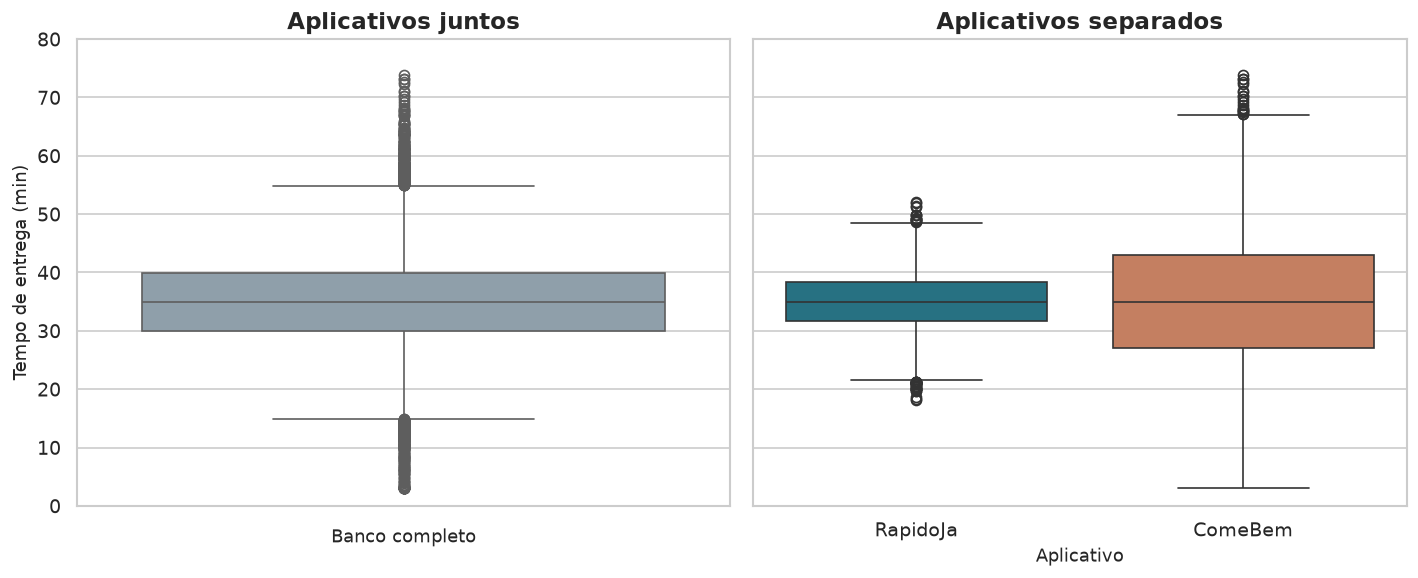

In [38]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

sns.boxplot(y=dados["tempo_min"], color="#8AA0AF", ax=eixos[0])
eixos[0].set_title("Aplicativos juntos")
eixos[0].set_xlabel("Banco completo")
eixos[0].set_ylabel("Tempo de entrega (min)")
eixos[0].set_ylim(0, 80)

sns.boxplot(
    data=dados,
    x="app",
    y="tempo_min",
    hue="app",
    order=ORDEM_APPS,
    palette=CORES,
    legend=False,
    ax=eixos[1]
)
eixos[1].set_title("Aplicativos separados")
eixos[1].set_xlabel("Aplicativo")
eixos[1].set_ylabel("Tempo de entrega (min)")

fig.tight_layout()
plt.show()

### Os pedidos sinalizados devem ser retirados?

Verificamos quantos pedidos sinalizados ultrapassaram 50 minutos, pois esse é o limite que gera desconto. Essa conferência ajuda a avaliar o impacto que uma exclusão teria na pergunta do projeto.

In [39]:
print("Entre os outliers dos aplicativos juntos:")
print("Pedidos acima de 50 min:",
      (outliers_total["tempo_min"] > 50).sum())

print("\nEntre os outliers próprios do RapidoJa:")
print("Pedidos acima de 50 min:",
      (outliers_rapidoja["tempo_min"] > 50).sum())

print("\nEntre os outliers próprios do ComeBem:")
print("Pedidos acima de 50 min:",
      (outliers_comebem["tempo_min"] > 50).sum())

Entre os outliers dos aplicativos juntos:
Pedidos acima de 50 min: 248

Entre os outliers próprios do RapidoJa:
Pedidos acima de 50 min: 4

Entre os outliers próprios do ComeBem:
Pedidos acima de 50 min: 20


### Interpretação

Com os dois aplicativos juntos, os limites foram de **14,9 a 54,9 minutos**. Esse critério sinalizou **478 pedidos do ComeBem e nenhum do RapidoJa**. O resultado do RapidoJa é zero porque todos os seus tempos observados, de 18,1 a 52,0 minutos, estão dentro dos limites conjuntos.

Ao calcular os limites separadamente, foram sinalizados **45 pedidos do RapidoJa**, fora do intervalo de 21,4 a 48,6 minutos, e **20 pedidos do ComeBem**, acima do intervalo de 3,0 a 67,0 minutos. As contagens mudam porque os limites dependem da dispersão do conjunto analisado.

**Os pedidos sinalizados serão mantidos na análise principal.** A regra de 1,5 × AIQ indica tempos incomuns, mas não comprova erro de registro. Além disso, parte desses pedidos ultrapassou 50 minutos e é relevante para avaliar os descontos. Sem evidência de erro nas informações fornecidas, retirá-los alteraria a resposta à pergunta do projeto.

## 6. Relação entre distância e tempo de entrega

Analisamos a relação entre `distancia_km` e `tempo_min` separadamente para RapidoJa e ComeBem. Em cada aplicativo, ajustamos uma reta:

**tempo previsto = intercepto + inclinação × distância**

A inclinação indica quantos minutos a reta acrescenta para cada quilômetro. O coeficiente de correlação de Pearson, `r`, indica a direção e a intensidade da associação linear entre distância e tempo. Um `r` positivo indica que distâncias maiores tendem a acompanhar tempos maiores.

In [40]:
ajuste_rapidoja = stats.linregress(
    rapidoja["distancia_km"],
    rapidoja["tempo_min"]
)

ajuste_comebem = stats.linregress(
    comebem["distancia_km"],
    comebem["tempo_min"]
)

print("RAPIDOJA")
print(f"Intercepto: {ajuste_rapidoja.intercept:.3f} min")
print(f"Inclinação: {ajuste_rapidoja.slope:.3f} min/km")
print(f"Correlação r: {ajuste_rapidoja.rvalue:.3f}")
print(f"R²: {ajuste_rapidoja.rvalue**2:.1%}")

print("\nCOMEBEM")
print(f"Intercepto: {ajuste_comebem.intercept:.3f} min")
print(f"Inclinação: {ajuste_comebem.slope:.3f} min/km")
print(f"Correlação r: {ajuste_comebem.rvalue:.3f}")
print(f"R²: {ajuste_comebem.rvalue**2:.1%}")

RAPIDOJA
Intercepto: 24.529 min
Inclinação: 2.577 min/km
Correlação r: 0.603
R²: 36.4%

COMEBEM
Intercepto: 25.019 min
Inclinação: 2.502 min/km
Correlação r: 0.251
R²: 6.3%


### Tempo previsto para uma entrega de 6 km

Substituímos `distância = 6` na reta de cada aplicativo. A previsão representa o tempo indicado pela reta para essa distância; uma entrega individual pode levar mais ou menos tempo.

In [41]:
previsao_6_rapidoja = (
    ajuste_rapidoja.intercept + ajuste_rapidoja.slope * 6
)

previsao_6_comebem = (
    ajuste_comebem.intercept + ajuste_comebem.slope * 6
)

print(f"RapidoJa — previsão para 6 km: {previsao_6_rapidoja:.2f} min")
print(f"ComeBem — previsão para 6 km: {previsao_6_comebem:.2f} min")

print("\nFaixas de distância observadas:")
print(f"RapidoJa: {rapidoja['distancia_km'].min():.1f} a "
      f"{rapidoja['distancia_km'].max():.1f} km")
print(f"ComeBem: {comebem['distancia_km'].min():.1f} a "
      f"{comebem['distancia_km'].max():.1f} km")

RapidoJa — previsão para 6 km: 39.99 min
ComeBem — previsão para 6 km: 40.03 min

Faixas de distância observadas:
RapidoJa: 0.5 a 9.2 km
ComeBem: 0.5 a 8.0 km


### Dispersão e retas ajustadas

Cada ponto representa um pedido: sua posição horizontal é a distância e sua posição vertical é o tempo de entrega. A reta resume a tendência linear; o ponto preto marca a previsão para 6 km. Os gráficos usam as mesmas escalas para permitir a comparação direta.

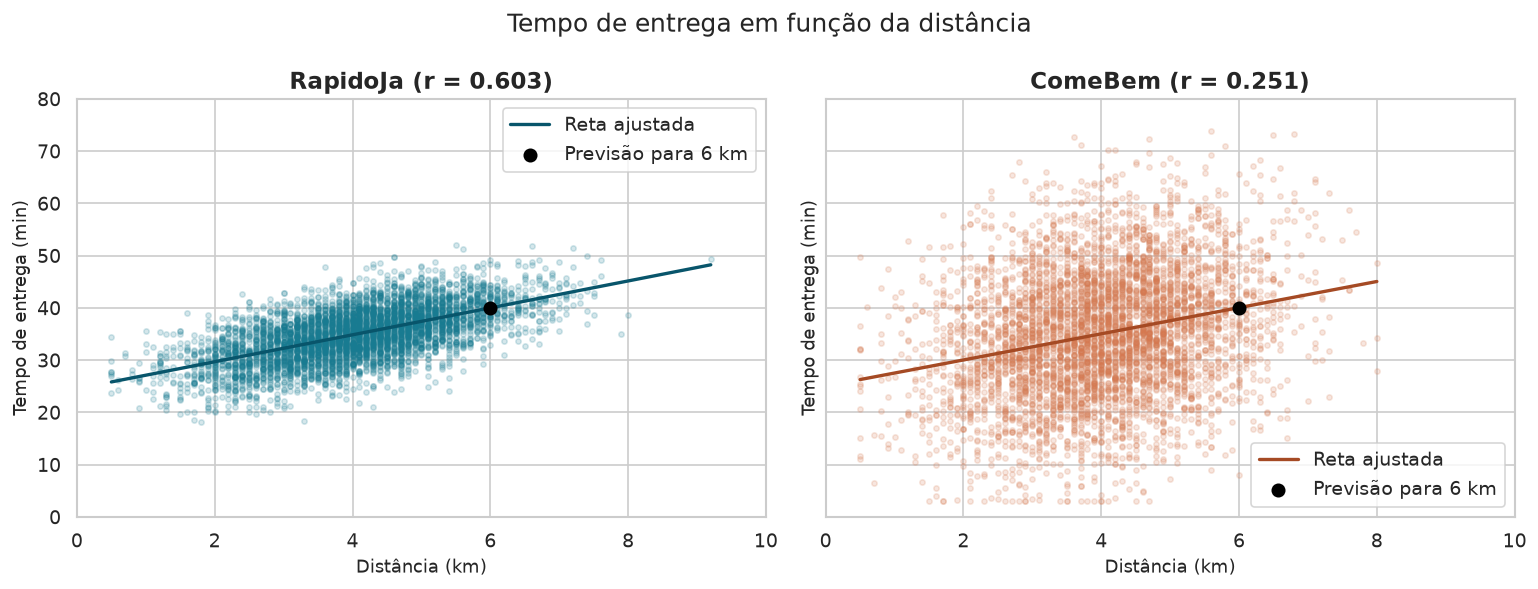

In [42]:
distancias_rapidoja = np.linspace(
    rapidoja["distancia_km"].min(),
    rapidoja["distancia_km"].max(),
    100
)

distancias_comebem = np.linspace(
    comebem["distancia_km"].min(),
    comebem["distancia_km"].max(),
    100
)

fig, eixos = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)

eixos[0].scatter(
    rapidoja["distancia_km"], rapidoja["tempo_min"],
    s=10, alpha=0.18, color=CORES["RapidoJa"]
)
eixos[0].plot(
    distancias_rapidoja,
    ajuste_rapidoja.intercept + ajuste_rapidoja.slope * distancias_rapidoja,
    color="#08556B", linewidth=2, label="Reta ajustada"
)
eixos[0].scatter(
    6, previsao_6_rapidoja,
    color="black", s=55, zorder=5, label="Previsão para 6 km"
)
eixos[0].set_title(f"RapidoJa (r = {ajuste_rapidoja.rvalue:.3f})")
eixos[0].set_xlabel("Distância (km)")
eixos[0].set_ylabel("Tempo de entrega (min)")
eixos[0].legend()

eixos[1].scatter(
    comebem["distancia_km"], comebem["tempo_min"],
    s=10, alpha=0.18, color=CORES["ComeBem"]
)
eixos[1].plot(
    distancias_comebem,
    ajuste_comebem.intercept + ajuste_comebem.slope * distancias_comebem,
    color="#A54A24", linewidth=2, label="Reta ajustada"
)
eixos[1].scatter(
    6, previsao_6_comebem,
    color="black", s=55, zorder=5, label="Previsão para 6 km"
)
eixos[1].set_title(f"ComeBem (r = {ajuste_comebem.rvalue:.3f})")
eixos[1].set_xlabel("Distância (km)")
eixos[1].set_ylabel("Tempo de entrega (min)")
eixos[1].legend()

eixos[0].set_xlim(0, 10)
eixos[0].set_ylim(0, 80)

fig.suptitle("Tempo de entrega em função da distância")
fig.tight_layout()
plt.show()

### Dispersão ao redor das retas

Para entender a diferença entre os valores de `r`, observamos os resíduos: a diferença entre o tempo registrado e o tempo indicado pela reta para a distância daquele pedido. Um desvio padrão maior dos resíduos significa que a distância, sozinha, deixa mais variação dos tempos sem representar.

In [43]:
residuos_rapidoja = rapidoja["tempo_min"] - (
    ajuste_rapidoja.intercept
    + ajuste_rapidoja.slope * rapidoja["distancia_km"]
)

residuos_comebem = comebem["tempo_min"] - (
    ajuste_comebem.intercept
    + ajuste_comebem.slope * comebem["distancia_km"]
)

print("Desvio padrão das distâncias:")
print(f"RapidoJa: {rapidoja['distancia_km'].std(ddof=0):.2f} km")
print(f"ComeBem: {comebem['distancia_km'].std(ddof=0):.2f} km")

print("\nDesvio padrão dos resíduos:")
print(f"RapidoJa: {residuos_rapidoja.std(ddof=0):.2f} min")
print(f"ComeBem: {residuos_comebem.std(ddof=0):.2f} min")

Desvio padrão das distâncias:
RapidoJa: 1.18 km
ComeBem: 1.19 km

Desvio padrão dos resíduos:
RapidoJa: 4.04 min
ComeBem: 11.50 min


### Interpretação

Distâncias maiores estão associadas a tempos de entrega maiores nos dois aplicativos. No RapidoJa, a reta ajustada é aproximadamente **tempo = 24,529 + 2,577 × distância**, com **r = 0,603** e **R² = 36,4%**. No ComeBem, a reta é **tempo = 25,019 + 2,502 × distância**, com **r = 0,251** e **R² = 6,3%**. As inclinações indicam um acréscimo próximo de 2,5 minutos por quilômetro nos dois casos.

Para uma distância de **6 km**, as retas preveem **39,99 minutos no RapidoJa** e **40,03 minutos no ComeBem**. São previsões da tendência média, não garantias para uma entrega individual. Seis quilômetros está dentro da faixa de distâncias observada em ambos os aplicativos.

Os valores de `r` diferem principalmente porque os tempos do ComeBem se espalham muito mais ao redor da reta. O desvio padrão dos resíduos é de **11,50 minutos no ComeBem**, contra **4,04 minutos no RapidoJa**, enquanto a dispersão das distâncias e as inclinações são parecidas. Assim, a distância tem uma associação linear mais clara com o tempo no RapidoJa. Os dados mostram essa diferença estatística, mas não permitem determinar sua causa operacional.

## 7. Comparação dos tempos médios entre os aplicativos

Vamos investigar se o tempo médio de entrega difere entre RapidoJa e ComeBem. Para isso, comparamos amostras independentes de 15, 100 e 1000 pedidos **por aplicativo** e, por fim, todos os pedidos disponíveis.

Em cada amostragem, usamos `random_state=67` e sorteamos pedidos sem reposição. Mantemos todos os valores observados, inclusive os identificados como possíveis outliers na etapa 5.

### 7.1 Definição dos grupos

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

tempo_rapidoja = dados.loc[dados["app"] == "RapidoJa", "tempo_min"]
tempo_comebem = dados.loc[dados["app"] == "ComeBem", "tempo_min"]

print(f"RapidoJa: {len(tempo_rapidoja)} pedidos")
print(f"Média: {tempo_rapidoja.mean():.3f} min")
print(f"Desvio padrão: {tempo_rapidoja.std(ddof=0):.3f} min")

print()

print(f"ComeBem: {len(tempo_comebem)} pedidos")
print(f"Média: {tempo_comebem.mean():.3f} min")
print(f"Desvio padrão: {tempo_comebem.std(ddof=0):.3f} min")

RapidoJa: 5011 pedidos
Média: 34.913 min
Desvio padrão: 5.061 min

ComeBem: 4989 pedidos
Média: 35.021 min
Desvio padrão: 11.876 min


### 7.2 Hipóteses e critério de decisão

Queremos verificar se os dois aplicativos têm tempos médios de entrega diferentes. As hipóteses são as mesmas nas quatro comparações:

- **H₀:** a média do RapidoJa é igual à média do ComeBem.
- **H₁:** as médias dos dois aplicativos são diferentes.
- **Tipo de teste:** bicaudal, pois qualquer diferença entre as médias nos interessa.
- **Nível de significância:** 5% (α = 0,05).

Usamos o **teste t de Welch** para comparar os dois grupos independentes. Ele é apropriado aqui porque os tempos do ComeBem apresentam dispersão bem maior que os do RapidoJa. A estatística do teste é:

$$
t = \frac{\bar{x}_{RJ} - \bar{x}_{CB}}
{\sqrt{\frac{s_{RJ}^{2}}{n_{RJ}} + \frac{s_{CB}^{2}}{n_{CB}}}}
$$

Nessa fórmula, as barras sobre os \(x\) indicam as médias das amostras; \(s\) representa o desvio padrão amostral; e \(n\), a quantidade de pedidos de cada aplicativo.

Em cada comparação, apresentaremos **t**, **graus de liberdade**, **valor de p** e **tamanho de efeito**. O tamanho de efeito será mostrado como diferença entre médias, em minutos, e como **d de Cohen**, em unidades de desvio padrão. Também calcularemos um **intervalo de 95% para a diferença entre as médias**.

Se **p < 0,05**, rejeitamos H₀. Caso contrário, não rejeitamos H₀. Uma diferença negativa, calculada como **RapidoJa − ComeBem**, significa que o RapidoJa teve menor tempo médio na amostra analisada.

### 7.3 Amostras de 15 pedidos por aplicativo

In [45]:
amostras_15 = dados.groupby("app").sample(n=15, random_state=67)

print("Pedidos sorteados por aplicativo:")
print(amostras_15["app"].value_counts())

amostra_rj_15 = amostras_15.loc[amostras_15["app"] == "RapidoJa", "tempo_min"]
amostra_cb_15 = amostras_15.loc[amostras_15["app"] == "ComeBem", "tempo_min"]

teste_15 = stats.ttest_ind(
    amostra_rj_15,
    amostra_cb_15,
    equal_var=False,
    alternative="two-sided"
)

dif_15 = amostra_rj_15.mean() - amostra_cb_15.mean()
dp_combinado_15 = np.sqrt(
    (amostra_rj_15.var(ddof=1) + amostra_cb_15.var(ddof=1)) / 2
)
d_15 = dif_15 / dp_combinado_15
ic_15 = teste_15.confidence_interval(confidence_level=0.95)

print()
print(f"Média RapidoJa: {amostra_rj_15.mean():.3f} min")
print(f"Média ComeBem: {amostra_cb_15.mean():.3f} min")
print(f"Diferença RJ - CB: {dif_15:.3f} min")
print(f"t = {teste_15.statistic:.3f}; gl = {teste_15.df:.3f}; p = {teste_15.pvalue:.4f}")
print(f"d de Cohen = {d_15:.3f}")
print(f"IC 95% da diferença: [{ic_15.low:.3f}; {ic_15.high:.3f}] min")

Pedidos sorteados por aplicativo:
app
ComeBem     15
RapidoJa    15
Name: count, dtype: int64

Média RapidoJa: 34.913 min
Média ComeBem: 37.493 min
Diferença RJ - CB: -2.580 min
t = -0.734; gl = 16.923; p = 0.4730
d de Cohen = -0.268
IC 95% da diferença: [-9.998; 4.838] min


### 7.4 Amostras de 100 pedidos por aplicativo

In [46]:
amostras_100 = dados.groupby("app").sample(n=100, random_state=67)

print("Pedidos sorteados por aplicativo:")
print(amostras_100["app"].value_counts())

amostra_rj_100 = amostras_100.loc[amostras_100["app"] == "RapidoJa", "tempo_min"]
amostra_cb_100 = amostras_100.loc[amostras_100["app"] == "ComeBem", "tempo_min"]

teste_100 = stats.ttest_ind(
    amostra_rj_100,
    amostra_cb_100,
    equal_var=False,
    alternative="two-sided"
)

dif_100 = amostra_rj_100.mean() - amostra_cb_100.mean()
dp_combinado_100 = np.sqrt(
    (amostra_rj_100.var(ddof=1) + amostra_cb_100.var(ddof=1)) / 2
)
d_100 = dif_100 / dp_combinado_100
ic_100 = teste_100.confidence_interval(confidence_level=0.95)

print()
print(f"Média RapidoJa: {amostra_rj_100.mean():.3f} min")
print(f"Média ComeBem: {amostra_cb_100.mean():.3f} min")
print(f"Diferença RJ - CB: {dif_100:.3f} min")
print(f"t = {teste_100.statistic:.3f}; gl = {teste_100.df:.3f}; p = {teste_100.pvalue:.4f}")
print(f"d de Cohen = {d_100:.3f}")
print(f"IC 95% da diferença: [{ic_100.low:.3f}; {ic_100.high:.3f}] min")

Pedidos sorteados por aplicativo:
app
ComeBem     100
RapidoJa    100
Name: count, dtype: int64

Média RapidoJa: 35.092 min
Média ComeBem: 35.711 min
Diferença RJ - CB: -0.619 min
t = -0.508; gl = 138.994; p = 0.6125
d de Cohen = -0.072
IC 95% da diferença: [-3.030; 1.792] min


### 7.5 Amostras de 1000 pedidos por aplicativo

In [47]:
amostras_1000 = dados.groupby("app").sample(n=1000, random_state=67)

print("Pedidos sorteados por aplicativo:")
print(amostras_1000["app"].value_counts())

amostra_rj_1000 = amostras_1000.loc[amostras_1000["app"] == "RapidoJa", "tempo_min"]
amostra_cb_1000 = amostras_1000.loc[amostras_1000["app"] == "ComeBem", "tempo_min"]

teste_1000 = stats.ttest_ind(
    amostra_rj_1000,
    amostra_cb_1000,
    equal_var=False,
    alternative="two-sided"
)

dif_1000 = amostra_rj_1000.mean() - amostra_cb_1000.mean()
dp_combinado_1000 = np.sqrt(
    (amostra_rj_1000.var(ddof=1) + amostra_cb_1000.var(ddof=1)) / 2
)
d_1000 = dif_1000 / dp_combinado_1000
ic_1000 = teste_1000.confidence_interval(confidence_level=0.95)

print()
print(f"Média RapidoJa: {amostra_rj_1000.mean():.3f} min")
print(f"Média ComeBem: {amostra_cb_1000.mean():.3f} min")
print(f"Diferença RJ - CB: {dif_1000:.3f} min")
print(f"t = {teste_1000.statistic:.3f}; gl = {teste_1000.df:.3f}; p = {teste_1000.pvalue:.4f}")
print(f"d de Cohen = {d_1000:.3f}")
print(f"IC 95% da diferença: [{ic_1000.low:.3f}; {ic_1000.high:.3f}] min")

Pedidos sorteados por aplicativo:
app
ComeBem     1000
RapidoJa    1000
Name: count, dtype: int64

Média RapidoJa: 34.799 min
Média ComeBem: 34.893 min
Diferença RJ - CB: -0.094 min
t = -0.231; gl = 1361.056; p = 0.8171
d de Cohen = -0.010
IC 95% da diferença: [-0.891; 0.703] min


### 7.6 Comparação com todos os pedidos

Agora utilizamos os 5.011 pedidos do RapidoJa e os 4.989 do ComeBem. Não há sorteio nessa comparação; a semente se aplica apenas às três amostragens anteriores.

In [48]:
teste_todos = stats.ttest_ind(
    tempo_rapidoja,
    tempo_comebem,
    equal_var=False,
    alternative="two-sided"
)

dif_todos = tempo_rapidoja.mean() - tempo_comebem.mean()

dp_combinado_todos = np.sqrt(
    (
        (len(tempo_rapidoja) - 1) * tempo_rapidoja.var(ddof=1)
        + (len(tempo_comebem) - 1) * tempo_comebem.var(ddof=1)
    )
    / (len(tempo_rapidoja) + len(tempo_comebem) - 2)
)

d_todos = dif_todos / dp_combinado_todos
ic_todos = teste_todos.confidence_interval(confidence_level=0.95)

print(f"RapidoJa: {len(tempo_rapidoja)} pedidos; média = {tempo_rapidoja.mean():.3f} min")
print(f"ComeBem: {len(tempo_comebem)} pedidos; média = {tempo_comebem.mean():.3f} min")
print(f"Diferença RJ - CB: {dif_todos:.3f} min")
print(f"t = {teste_todos.statistic:.3f}; gl = {teste_todos.df:.3f}; p = {teste_todos.pvalue:.4f}")
print(f"d de Cohen = {d_todos:.3f}")
print(f"IC 95% da diferença: [{ic_todos.low:.3f}; {ic_todos.high:.3f}] min")

RapidoJa: 5011 pedidos; média = 34.913 min
ComeBem: 4989 pedidos; média = 35.021 min
Diferença RJ - CB: -0.109 min
t = -0.595; gl = 6735.198; p = 0.5519
d de Cohen = -0.012
IC 95% da diferença: [-0.467; 0.249] min


### 7.7 Resumo dos quatro cenários

A primeira tabela reúne os tamanhos das amostras, médias e desvios padrão. A segunda mostra os resultados dos testes e a decisão com α = 0,05. A diferença foi calculada sempre como **média RapidoJa menos média ComeBem**.

In [49]:
resumo_7 = pd.DataFrame({
    "Cenário": [
        "15 por aplicativo",
        "100 por aplicativo",
        "1000 por aplicativo",
        "Todos os pedidos"
    ],
    "n RJ": [
        len(amostra_rj_15),
        len(amostra_rj_100),
        len(amostra_rj_1000),
        len(tempo_rapidoja)
    ],
    "n CB": [
        len(amostra_cb_15),
        len(amostra_cb_100),
        len(amostra_cb_1000),
        len(tempo_comebem)
    ],
    "Média RJ (min)": [
        amostra_rj_15.mean(),
        amostra_rj_100.mean(),
        amostra_rj_1000.mean(),
        tempo_rapidoja.mean()
    ],
    "Média CB (min)": [
        amostra_cb_15.mean(),
        amostra_cb_100.mean(),
        amostra_cb_1000.mean(),
        tempo_comebem.mean()
    ],
    "DP RJ (min)": [
        amostra_rj_15.std(ddof=1),
        amostra_rj_100.std(ddof=1),
        amostra_rj_1000.std(ddof=1),
        tempo_rapidoja.std(ddof=1)
    ],
    "DP CB (min)": [
        amostra_cb_15.std(ddof=1),
        amostra_cb_100.std(ddof=1),
        amostra_cb_1000.std(ddof=1),
        tempo_comebem.std(ddof=1)
    ],
    "Diferença (min)": [dif_15, dif_100, dif_1000, dif_todos],
    "t": [
        teste_15.statistic,
        teste_100.statistic,
        teste_1000.statistic,
        teste_todos.statistic
    ],
    "gl": [teste_15.df, teste_100.df, teste_1000.df, teste_todos.df],
    "p": [teste_15.pvalue, teste_100.pvalue, teste_1000.pvalue, teste_todos.pvalue],
    "d de Cohen": [d_15, d_100, d_1000, d_todos],
    "IC inferior (min)": [ic_15.low, ic_100.low, ic_1000.low, ic_todos.low],
    "IC superior (min)": [ic_15.high, ic_100.high, ic_1000.high, ic_todos.high]
})

resumo_7["Decisão"] = np.where(
    resumo_7["p"] < 0.05,
    "Rejeitar H0",
    "Não rejeitar H0"
)

display(
    resumo_7[
        ["Cenário", "n RJ", "n CB", "Média RJ (min)", "Média CB (min)",
         "DP RJ (min)", "DP CB (min)"]
    ].round(3)
)

display(
    resumo_7[
        ["Cenário", "Diferença (min)", "t", "gl", "p", "d de Cohen",
         "IC inferior (min)", "IC superior (min)", "Decisão"]
    ].round(3)
)

,Cenário,n RJ,n CB,Média RJ (min),Média CB (min),DP RJ (min),DP CB (min)
0,15 por aplicativo,15,15,34.913,37.493,4.206,12.947
1,100 por aplicativo,100,100,35.092,35.711,5.089,11.079
2,1000 por aplicativo,1000,1000,34.799,34.893,5.108,11.795
3,Todos os pedidos,5011,4989,34.913,35.021,5.061,11.878


,Cenário,Diferença (min),t,gl,p,d de Cohen,IC inferior (min),IC superior (min),Decisão
0,15 por aplicativo,-2.580,-0.734,16.923,0.473,-0.268,-9.998,4.838,Não rejeitar H0
1,100 por aplicativo,-0.619,-0.508,138.994,0.612,-0.072,-3.030,1.792,Não rejeitar H0
2,1000 por aplicativo,-0.094,-0.231,1361.056,0.817,-0.010,-0.891,0.703,Não rejeitar H0
3,Todos os pedidos,-0.109,-0.595,6735.198,0.552,-0.012,-0.467,0.249,Não rejeitar H0


### 7.8 Visualização das diferenças

Cada ponto representa a diferença entre as médias dos aplicativos. A linha horizontal mostra o intervalo de 95% dessa diferença. A linha vertical tracejada marca diferença igual a zero. Pontos à esquerda de zero indicam média menor para RapidoJa.

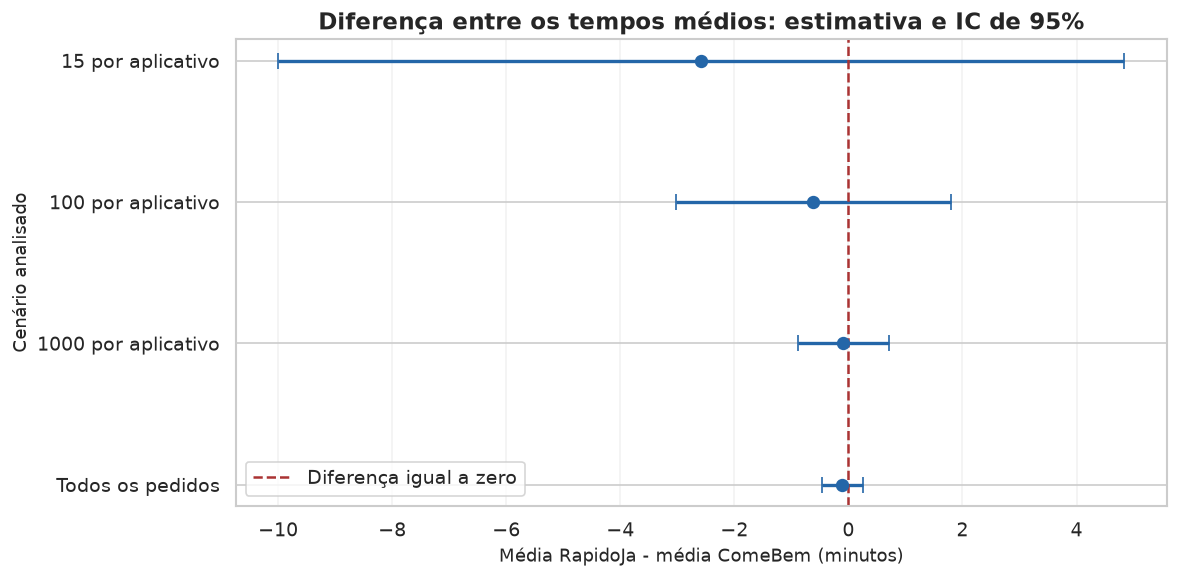

In [50]:
fig, ax = plt.subplots(figsize=(10, 5))

posicoes = np.arange(len(resumo_7))

erro_esquerda = resumo_7["Diferença (min)"] - resumo_7["IC inferior (min)"]
erro_direita = resumo_7["IC superior (min)"] - resumo_7["Diferença (min)"]

ax.errorbar(
    resumo_7["Diferença (min)"],
    posicoes,
    xerr=np.vstack([erro_esquerda, erro_direita]),
    fmt="o",
    color="#2466a8",
    ecolor="#2466a8",
    elinewidth=2,
    capsize=5,
    markersize=7
)

ax.axvline(
    0,
    color="#aa3333",
    linestyle="--",
    linewidth=1.5,
    label="Diferença igual a zero"
)

ax.set_yticks(posicoes, resumo_7["Cenário"])
ax.invert_yaxis()
ax.set_xlabel("Média RapidoJa - média ComeBem (minutos)")
ax.set_ylabel("Cenário analisado")
ax.set_title("Diferença entre os tempos médios: estimativa e IC de 95%")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
ax.legend()

plt.tight_layout()
plt.show()

### 7.9 Interpretação

Em todos os cenários, a média observada do RapidoJa ficou abaixo da média do ComeBem. Contudo, nenhuma das quatro comparações apresentou evidência estatística suficiente para rejeitar a hipótese de médias iguais ao nível de 5%.

Com **15 pedidos por aplicativo**, a diferença entre as médias foi de **−2,580 min** (RapidoJa − ComeBem), mas o teste de Welch resultou em **t = −0,734**, **gl = 16,923** e **p = 0,473**. O tamanho de efeito padronizado foi **d = −0,268**, e o IC de 95% para a diferença foi **[−9,998; 4,838] min**. A amplitude do intervalo mostra a baixa precisão dessa amostra pequena.

Com **100 pedidos por aplicativo**, a diferença foi de **−0,619 min**, com **t = −0,508**, **gl = 138,994**, **p = 0,612** e **d = −0,072**. O IC de 95% foi **[−3,030; 1,792] min**.

Com **1000 pedidos por aplicativo**, a diferença foi de **−0,094 min**, com **t = −0,231**, **gl = 1361,056**, **p = 0,817** e **d = −0,010**. O IC de 95% foi **[−0,891; 0,703] min**.

Considerando **todos os 10.000 pedidos**, as médias foram **34,913 min** para RapidoJa e **35,021 min** para ComeBem: diferença de **−0,109 min**, aproximadamente **6,5 segundos**. A aplicação solicitada do teste de Welch forneceu **t = −0,595**, **gl = 6735,198**, **p = 0,552** e **d = −0,012**; o IC de 95% foi **[−0,467; 0,249] min**.

Portanto, **não rejeitamos H₀ em nenhum cenário**. Isso não prova que as médias sejam exatamente iguais; indica que estas comparações não encontraram evidência de diferença. No banco completo, a diferença observada entre as médias é muito pequena. A maior distinção entre os aplicativos permanece na **dispersão dos tempos**, relevante para entregas demoradas e para a política de desconto.

Como o enunciado define os 10.000 pedidos como a população deste exercício, a diferença de **−0,109 min** descreve exatamente esse banco. O valor de p e o IC calculados com todos os pedidos só têm interpretação inferencial se pensarmos nesses registros como representantes de entregas futuras. Além disso, a análise com 15 pedidos por grupo requer cautela: amostras pequenas são mais sensíveis a valores extremos e a desvios da normalidade. Os quatro cenários representam o mesmo contraste em tamanhos diferentes, não quatro confirmações independentes.

## 8. Intervalos de confiança e tamanho necessário da amostra

Estimamos separadamente o tempo médio de cada aplicativo com amostras de **15, 100 e 1000 pedidos por grupo**, sorteadas com `random_state=67`. Para cada amostra, calculamos um intervalo de confiança (IC) de 95%:

$$
IC_{95\%}=\bar{x}\ \pm\ t_{0.975,\ n-1}\frac{s}{\sqrt{n}}
$$

Nessa expressão, $\bar{x}$ é a média da amostra, $s$ é seu desvio padrão, $n$ é a quantidade de pedidos e $t_{0.975,\ n-1}$ é o valor crítico da distribuição t com `n − 1` graus de liberdade. O produto do valor crítico pelo erro padrão é a **margem de erro**.

Seguimos a fórmula de IC indicada no enunciado, sem correção para população finita. Os 10.000 pedidos constituem a população deste exercício; portanto, suas médias podem ser calculadas diretamente.

### 8.1 Intervalos de 95% para cada tamanho de amostra

In [51]:
amostras_15 = dados.groupby("app").sample(n=15, random_state=67)
amostras_100 = dados.groupby("app").sample(n=100, random_state=67)
amostras_1000 = dados.groupby("app").sample(n=1000, random_state=67)

base_ic = pd.concat(
    [
        amostras_15.assign(cenario="15 por aplicativo"),
        amostras_100.assign(cenario="100 por aplicativo"),
        amostras_1000.assign(cenario="1000 por aplicativo")
    ],
    ignore_index=True
)

resumo_ic = (
    base_ic.groupby(["cenario", "app"])["tempo_min"]
    .agg(n="size", media_min="mean", dp_min="std")
    .reset_index()
)

resumo_ic["app"] = pd.Categorical(
    resumo_ic["app"],
    categories=["RapidoJa", "ComeBem"],
    ordered=True
)

resumo_ic = resumo_ic.sort_values(["n", "app"]).reset_index(drop=True)

resumo_ic["erro_padrao_min"] = resumo_ic["dp_min"] / np.sqrt(resumo_ic["n"])
resumo_ic["t_critico"] = stats.t.ppf(0.975, resumo_ic["n"] - 1)
resumo_ic["margem_min"] = resumo_ic["t_critico"] * resumo_ic["erro_padrao_min"]
resumo_ic["ic_inferior_min"] = resumo_ic["media_min"] - resumo_ic["margem_min"]
resumo_ic["ic_superior_min"] = resumo_ic["media_min"] + resumo_ic["margem_min"]

print("Componentes do cálculo:")
display(
    resumo_ic[
        ["cenario", "app", "n", "media_min", "dp_min",
         "erro_padrao_min", "t_critico"]
    ].round(3)
)

print("Intervalos de confiança de 95%:")
display(
    resumo_ic[
        ["cenario", "app", "n", "media_min", "margem_min",
         "ic_inferior_min", "ic_superior_min"]
    ].round(3)
)

Componentes do cálculo:


,cenario,app,n,media_min,dp_min,erro_padrao_min,t_critico
0,15 por aplicativo,RapidoJa,15,34.913,4.206,1.086,2.145
1,15 por aplicativo,ComeBem,15,37.493,12.947,3.343,2.145
2,100 por aplicativo,RapidoJa,100,35.092,5.089,0.509,1.984
3,100 por aplicativo,ComeBem,100,35.711,11.079,1.108,1.984
4,1000 por aplicativo,RapidoJa,1000,34.799,5.108,0.162,1.962
5,1000 por aplicativo,ComeBem,1000,34.893,11.795,0.373,1.962


Intervalos de confiança de 95%:


,cenario,app,n,media_min,margem_min,ic_inferior_min,ic_superior_min
0,15 por aplicativo,RapidoJa,15,34.913,2.329,32.584,37.243
1,15 por aplicativo,ComeBem,15,37.493,7.170,30.324,44.663
2,100 por aplicativo,RapidoJa,100,35.092,1.010,34.082,36.102
3,100 por aplicativo,ComeBem,100,35.711,2.198,33.513,37.909
4,1000 por aplicativo,RapidoJa,1000,34.799,0.317,34.482,35.116
5,1000 por aplicativo,ComeBem,1000,34.893,0.732,34.161,35.625


### 8.2 Comparação visual dos intervalos

Os pontos representam as médias obtidas nas amostras; as hastes verticais representam os respectivos ICs de 95%. A linha tracejada indica os **35 minutos anunciados** pelos aplicativos. O gráfico permite observar como os intervalos ficam mais estreitos quando aumentamos o tamanho da amostra.

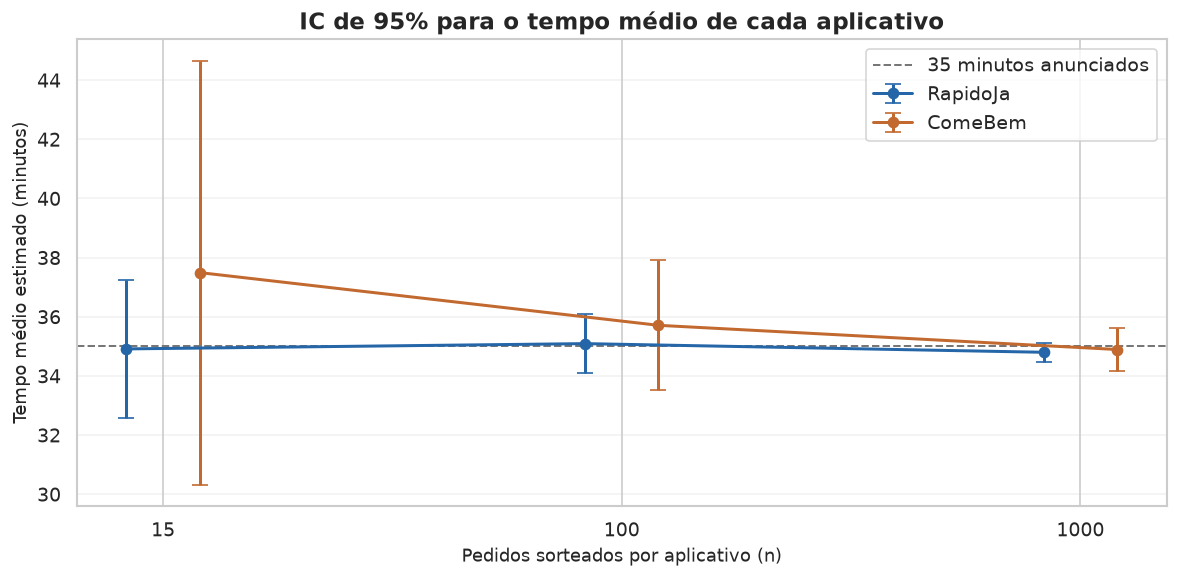

In [52]:
rj_ic = resumo_ic.loc[resumo_ic["app"] == "RapidoJa"].sort_values("n")
cb_ic = resumo_ic.loc[resumo_ic["app"] == "ComeBem"].sort_values("n")

posicoes = np.arange(3)

fig, ax = plt.subplots(figsize=(10, 5))

ax.errorbar(
    posicoes - 0.08,
    rj_ic["media_min"],
    yerr=rj_ic["margem_min"],
    fmt="o-",
    color="#2466a8",
    capsize=5,
    linewidth=1.8,
    label="RapidoJa"
)

ax.errorbar(
    posicoes + 0.08,
    cb_ic["media_min"],
    yerr=cb_ic["margem_min"],
    fmt="o-",
    color="#c26930",
    capsize=5,
    linewidth=1.8,
    label="ComeBem"
)

ax.axhline(
    35,
    color="#777777",
    linestyle="--",
    linewidth=1.2,
    label="35 minutos anunciados"
)

ax.set_xticks(posicoes, ["15", "100", "1000"])
ax.set_xlabel("Pedidos sorteados por aplicativo (n)")
ax.set_ylabel("Tempo médio estimado (minutos)")
ax.set_title("IC de 95% para o tempo médio de cada aplicativo")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend()

plt.tight_layout()
plt.show()

### 8.3 Quantos pedidos são necessários para uma margem de 1 minuto?

Para planejar uma amostra com IC de 95% e margem desejada de **1 minuto**, aplicamos a fórmula fornecida no enunciado:

$$
n=\left(\frac{1.96\,\sigma}{E}\right)^2
$$

Usamos $E=1$ minuto e, para cada aplicativo, o desvio padrão **populacional** calculado com todos os seus pedidos. Como não podemos coletar uma fração de pedido, arredondamos o resultado **para cima**.

In [53]:
tempo_rapidoja = dados.loc[dados["app"] == "RapidoJa", "tempo_min"]
tempo_comebem = dados.loc[dados["app"] == "ComeBem", "tempo_min"]

sigma_rj = tempo_rapidoja.std(ddof=0)
sigma_cb = tempo_comebem.std(ddof=0)

margem_desejada = 1

n_rj_calculado = (1.96 * sigma_rj / margem_desejada) ** 2
n_cb_calculado = (1.96 * sigma_cb / margem_desejada) ** 2

n_rj_necessario = int(np.ceil(n_rj_calculado))
n_cb_necessario = int(np.ceil(n_cb_calculado))

tamanho_necessario = pd.DataFrame({
    "Aplicativo": ["RapidoJa", "ComeBem"],
    "DP populacional (min)": [sigma_rj, sigma_cb],
    "n calculado": [n_rj_calculado, n_cb_calculado],
    "Pedidos necessários": [n_rj_necessario, n_cb_necessario]
})

display(tamanho_necessario.round(3))

,Aplicativo,DP populacional (min),n calculado,Pedidos necessários
0,RapidoJa,5.061,98.38,99
1,ComeBem,11.876,541.85,542


### 8.4 Interpretação

Com **15 pedidos por aplicativo**, o IC de 95% do tempo médio foi **[32,584; 37,243] min** para RapidoJa e **[30,324; 44,663] min** para ComeBem. As margens de erro foram, respectivamente, **2,329** e **7,170 min**: uma amostra pequena oferece pouca precisão, sobretudo para o ComeBem.

Com **100 pedidos por aplicativo**, os intervalos passaram a **[34,082; 36,102] min** para RapidoJa e **[33,513; 37,909] min** para ComeBem. As margens diminuíram para **1,010** e **2,198 min**.

Com **1000 pedidos por aplicativo**, os intervalos foram **[34,482; 35,116] min** para RapidoJa e **[34,161; 35,625] min** para ComeBem. As margens caíram para **0,317** e **0,732 min**. A tabela e o gráfico mostram que, para o mesmo tamanho de amostra, o IC do ComeBem permanece mais largo devido à maior dispersão de seus tempos.

As médias dos bancos completos são **34,913 min** para RapidoJa e **35,021 min** para ComeBem. Como esses bancos são tratados como a população do exercício, essas médias são conhecidas diretamente; os ICs acima mostram a precisão obtida quando usamos apenas parte dos pedidos.

Pela fórmula de planejamento indicada no enunciado, estimar cada média com **margem de 1 minuto e 95% de confiança** requer aproximadamente **99 pedidos RapidoJa** ou **542 pedidos ComeBem**, sempre arredondando para cima. Esses números são de planejamento: a margem efetiva de um IC t depende também da dispersão encontrada na amostra coletada.

## Pergunta final — qual aplicativo manter?

Comparamos os tempos médios, a variação dos tempos e a frequência **observada** de entregas acima de 50 minutos. Para expressar o impacto da política de desconto em uma mesma escala, calculamos quantos pedidos receberiam desconto **a cada 1000 pedidos**, com base na proporção observada em cada aplicativo.

In [54]:
descontos_rj = (tempo_rapidoja > 50).sum()
descontos_cb = (tempo_comebem > 50).sum()

taxa_desconto_rj = descontos_rj / len(tempo_rapidoja)
taxa_desconto_cb = descontos_cb / len(tempo_comebem)

resumo_final = pd.DataFrame({
    "Aplicativo": ["RapidoJa", "ComeBem"],
    "Pedidos analisados": [len(tempo_rapidoja), len(tempo_comebem)],
    "Tempo médio (min)": [tempo_rapidoja.mean(), tempo_comebem.mean()],
    "DP populacional (min)": [
        tempo_rapidoja.std(ddof=0),
        tempo_comebem.std(ddof=0)
    ],
    "Pedidos > 50 min": [descontos_rj, descontos_cb],
    "Taxa de desconto (%)": [
        taxa_desconto_rj * 100,
        taxa_desconto_cb * 100
    ],
    "Descontos por 1000": [
        taxa_desconto_rj * 1000,
        taxa_desconto_cb * 1000
    ]
})

display(resumo_final.round(3))

,Aplicativo,Pedidos analisados,Tempo médio (min),DP populacional (min),Pedidos > 50 min,Taxa de desconto (%),Descontos por 1000
0,RapidoJa,5011,34.913,5.061,4,0.080,0.798
1,ComeBem,4989,35.021,11.876,498,9.982,99.820


### Frequência de pedidos com desconto

O gráfico utiliza as proporções observadas no banco completo e as expressa por 1000 pedidos. A regra aplicada é `tempo_min > 50`.

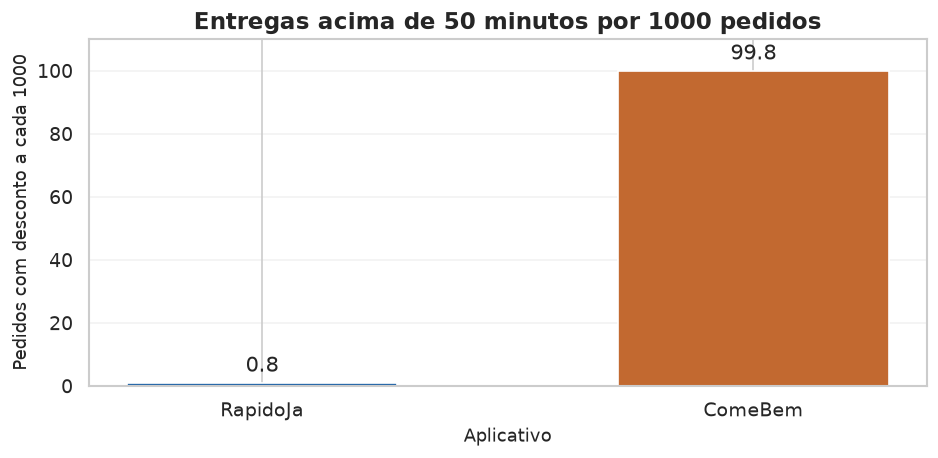

In [55]:
fig, ax = plt.subplots(figsize=(8, 4))

barras = ax.bar(
    resumo_final["Aplicativo"],
    resumo_final["Descontos por 1000"],
    color=["#2466a8", "#c26930"],
    width=0.55
)

ax.bar_label(barras, fmt="%.1f", padding=4)
ax.set_ylim(0, 110)
ax.set_xlabel("Aplicativo")
ax.set_ylabel("Pedidos com desconto a cada 1000")
ax.set_title("Entregas acima de 50 minutos por 1000 pedidos")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Resposta final

**Recomendamos manter o RapidoJa**, considerando os tempos de entrega e a política de desconto descritos no projeto.

As médias dos aplicativos são muito próximas: **34,913 min** para RapidoJa e **35,021 min** para ComeBem, diferença de aproximadamente **0,109 min** ou **6,5 segundos** no banco completo. Na etapa 7, o teste de Welch não encontrou evidência de diferença entre as médias ao nível de 5%. Portanto, a média isolada oferece pouca vantagem para decidir o contrato.

A diferença prática aparece na **regularidade das entregas**. O desvio padrão populacional é **5,061 min** no RapidoJa e **11,876 min** no ComeBem. Com a regra de desconto para entregas **acima de 50 minutos**, observamos **4 de 5.011 pedidos** com desconto no RapidoJa (**0,080%**) e **498 de 4.989** no ComeBem (**9,982%**).

Aplicadas a uma escala de **1000 pedidos**, essas taxas equivalem a aproximadamente **0,8 pedido com desconto no RapidoJa** e **99,8 no ComeBem** — diferença de cerca de **99 pedidos com desconto por 1000**. Esse é o impacto em **quantidade de descontos** solicitado pelo enunciado. O valor financeiro não pode ser calculado porque o banco não informa o valor de cada desconto.

Assim, entre dois aplicativos com tempos médios semelhantes, o RapidoJa apresentou entregas muito menos dispersas e uma frequência observada muito menor de pedidos sujeitos a desconto. Essa evidência sustenta sua escolha para a renovação do contrato, dentro dos critérios que o banco de dados permite avaliar.